# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Complete Laboratory Solutions — Sets 01 to 10
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Master Laboratory Notebook:** Unified compilation of all 10 laboratory sets featuring complete background theory, mathematical formulation, clean Python implementations, generated visualizations, result interpretations, and viva voce question-answer revision. Formatted for unified laboratory review and direct PDF export.

---

### Master Table of Contents
| Set | Focus Areas & Key Topics | Practical Problems | Viva Practice |
|:---|:---|:---|:---|
| [**Set 01**](#set-01--final-laboratory-examination) | Intelligent Agent & PEAS • BFS, DFS, Greedy • Iris k-NN | Q1, Q2, Q3 | [`Set_01/Set_01_D.py`](Set_01/Set_01_D.py) |
| [**Set 02**](#set-02--final-laboratory-examination) | Forward Chaining (Medical) • DLS & IDDFS • Linear Regression | Q1, Q2, Q3 | [`Set_02/Set_02_D.py`](Set_02/Set_02_D.py) |
| [**Set 03**](#set-03--final-laboratory-examination) | FOL Kinship Queries • A* Admissible Search • Iris K-Means | Q1, Q2, Q3 | [`Set_03/Set_03_D.py`](Set_03/Set_03_D.py) |
| [**Set 04**](#set-04--final-laboratory-examination) | Graph Traversal • WEKA J48 & IBk Cross-Validation • Regression | Q1, Q2, Q3 | [`Set_04/Set_04_D.py`](Set_04/Set_04_D.py) |
| [**Set 05**](#set-05--final-laboratory-examination) | 3-Location Vacuum Agent • Greedy vs A* • Decision Tree Pruning | Q1, Q2, Q3 | [`Set_05/Set_05_D.py`](Set_05/Set_05_D.py) |
| [**Set 06**](#set-06--final-laboratory-examination) | Rule Engine Eligibility • BFS, DFS, IDDFS • k-NN vs Decision Tree | Q1, Q2, Q3 | [`Set_06/Set_06_D.py`](Set_06/Set_06_D.py) |
| [**Set 07**](#set-07--final-laboratory-examination) | Family FOL Knowledge Base • Heuristic Sensitivity • Scaled K-Means | Q1, Q2, Q3 | [`Set_07/Set_07_D.py`](Set_07/Set_07_D.py) |
| [**Set 08**](#set-08--final-laboratory-examination) | DLS/IDDFS Root Tracing • WEKA IBk/J48 Preprocessing • Regression | Q1, Q2, Q3 | [`Set_08/Set_08_D.py`](Set_08/Set_08_D.py) |
| [**Set 09**](#set-09--final-laboratory-examination) | Branching Search • A* Admissibility • K-Means Elbow & Silhouette | Q1, Q2, Q3 | [`Set_09/Set_09_D.py`](Set_09/Set_09_D.py) |
| [**Set 10**](#set-10--final-laboratory-examination) | Integrated Agent • Shortest vs Cheapest Routes • Iris Metrics | Q1, Q2, Q3 | [`Set_10/Set_10_D.py`](Set_10/Set_10_D.py) |

**Execution note:** Open in JupyterLab, VS Code, or Google Colab with a standard Python 3 kernel. All outputs (terminal traces, tables, and matplotlib figures) are pre-executed and preserved for self-contained reading and high-resolution PDF generation.


---
# Set 01 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Intelligent Agent and PEAS | 25 |
| Q2 | BFS, DFS and Greedy Best-First | 30 |
| Q3 | Iris k-NN classification | 35 |
| Q4 | Viva: agent, PEAS, heuristics, k-NN, scaling | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_01/Set_01_A.py) | [Q2 / B](Set_01/Set_01_B.py) | [Q3 / C](Set_01/Set_01_C.py) | [Q4 / D: Viva practice](Set_01/Set_01_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Intelligent Agent and PEAS (25 marks)
**Question specification**  
Two-room vacuum world: A starts **Dirty**, B **Clean**, agent starts at **B**. Implement `Suck`, `Left`, `Right` and `NoOp`, stop when both rooms are clean, and display every percept-action pair. Also give PEAS for an autonomous office-document delivery robot.

### Theory and mathematical background
An **agent** senses the environment and selects an **action** from the current percept. A simple reflex rule depends on the current percept only; the rule `Dirty → Suck` is a condition-action rule.

A two-room agent that **stops when every room is clean** needs information beyond a purely local percept (either global sensing or internal state). Therefore the terminating variant is *reflex-style cleaning with global-state access*, not a strictly percept-only reflex agent.

Let $s_t$ denote the current environment and $a_t$ the selected action. A policy chooses $a_t=\pi(s_t)$, and the transition is $s_{t+1}=T(s_t,a_t)$. For the cleaning goal:
$$\text{NoOp when }\bigwedge_{r\in\mathcal{R}}\operatorname{Clean}(r).$$

**PEAS** describes Performance, Environment, Actuators, and Sensors.

### Algorithm / procedure
1. Inspect the current room and status. 
2. Return `NoOp` if the entire world is clean. 
3. Otherwise clean the current room if dirty; else move to the dirty room. 
4. Update state and print the trace.

In [7]:
def vacuum_policy(location, rooms):
    if all(status == 'Clean' for status in rooms.values()):
        return 'NoOp'
    if rooms[location] == 'Dirty':
        return 'Suck'
    return 'Left' if location == 'B' else 'Right'

rooms = {'A': 'Dirty', 'B': 'Clean'}
location = 'B'
trace = []
for step in range(1, 12):
    percept = (location, rooms[location])
    action = vacuum_policy(location, rooms)
    trace.append((step, percept, action, dict(rooms)))
    print(f'Step {step}: percept={percept}, action={action}, rooms(before)={rooms}')
    if action == 'NoOp': break
    if action == 'Suck': rooms[location] = 'Clean'
    elif action == 'Left': location = 'A'
    elif action == 'Right': location = 'B'
print('Final environment:', rooms)
assert all(v == 'Clean' for v in rooms.values())
assert trace[-1][2] == 'NoOp'


Step 1: percept=('B', 'Clean'), action=Left, rooms(before)={'A': 'Dirty', 'B': 'Clean'}
Step 2: percept=('A', 'Dirty'), action=Suck, rooms(before)={'A': 'Dirty', 'B': 'Clean'}
Step 3: percept=('A', 'Clean'), action=NoOp, rooms(before)={'A': 'Clean', 'B': 'Clean'}
Final environment: {'A': 'Clean', 'B': 'Clean'}


### PEAS — autonomous university document-delivery robot
| Component | Description |
|:--|:--|
| **Performance** | Correct deliveries, timely service, minimal energy usage, safety, privacy, few collisions |
| **Environment** | Office rooms, corridors, stairs/elevators, doors, staff, obstacles, changing pedestrian traffic |
| **Actuators** | Wheel motors, steering/brakes, robotic gripper/document locker, audio/display notifications |
| **Sensors** | Camera, lidar/ultrasonic, wheel odometry, inertial sensor, proximity and door sensors, map/location data |

**Important distinction:** In a strict simple-reflex agent, the percept is only *(current room, current cleanliness)*. Knowing *all rooms are clean* requires a wider percept or internal memory. This solution follows the question's stop requirement with observable global room states.

---
## Q2. BFS, DFS and Greedy Best-First Search (30 marks)
**Question specification**  
`A:{B,C}, B:{D,E}, C:{F}, D:{G}, E:{G}, F:{G}, G:{}`. Implement BFS, DFS, Greedy using `h(A..G)=(6,4,3,2,2,1,0)`. Show path and nodes expanded; compare.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

Greedy prioritizes $h(n)$; unlike BFS in an unweighted graph it does not guarantee the shallowest solution in general.

In [8]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

def greedy_unweighted(graph, h, start, goal):
    tie = count()
    heap = [(h[start], next(tie), start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(tie), nxt, path + [nxt]))
    return None, expanded

graph = {'A':['B','C'], 'B':['D','E'], 'C':['F'],
         'D':['G'], 'E':['G'], 'F':['G'], 'G':[]}
h = {'A':6,'B':4,'C':3,'D':2,'E':2,'F':1,'G':0}
for name, result in [('BFS', bfs(graph,'A','G')),
                     ('DFS', dfs(graph,'A','G')),
                     ('Greedy', greedy_unweighted(graph,h,'A','G'))]:
    path, expanded = result
    print(f'{name:7}: path={path} | expanded={expanded} | count={len(expanded)}')


BFS    : path=['A', 'B', 'D', 'G'] | expanded=['A', 'B', 'C', 'D', 'E', 'F', 'G'] | count=7
DFS    : path=['A', 'B', 'D', 'G'] | expanded=['A', 'B', 'D', 'G'] | count=4
Greedy : path=['A', 'C', 'F', 'G'] | expanded=['A', 'C', 'F', 'G'] | count=4


### Result interpretation and discussion
**Interpretation:** BFS expands in increasing path depth; DFS takes the first listed branch deeply, while Greedy uses the assigned heuristic values. Every listed expanded sequence **includes the goal when it is removed from the frontier**. Change the adjacency order or heuristic to see why expansion order is algorithm-dependent.

---
## Q3. Machine Learning — k-NN (35 marks)
**Question specification**  
Load Iris, stratified 70/30 train-test split with `random_state=42`; test $k=1,3,5,7$, identify the best test accuracy, print its confusion matrix, then standardize features and repeat that $k$.

### Theory and mathematical background
**k-Nearest Neighbors (k-NN)** predicts the majority label among the $k$ nearest training samples. A common distance is Euclidean:
$$d(\mathbf x,\mathbf z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$
Standardization rescales a feature using training-set statistics:
$$z_j=\frac{x_j-\mu_j^{\mathrm{train}}}{\sigma_j^{\mathrm{train}}}.$$
**Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$ for binary labels (or total correct / total cases for multiclass). A confusion matrix $C_{ij}$ counts instances of actual class $i$ predicted as class $j$. Fit scaling on training samples only to prevent leakage.

Iris samples: (150, 4) | train: 105 | test: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
 k  test_accuracy
 1       0.933333
 3       0.955556
 5       0.977778
 7       0.955556
Best k on this fixed test split: 5
Confusion matrix (rows=true, columns=predicted):
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
Unscaled accuracy: 0.9778
Scaled accuracy: 0.9111
Scaled confusion matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]


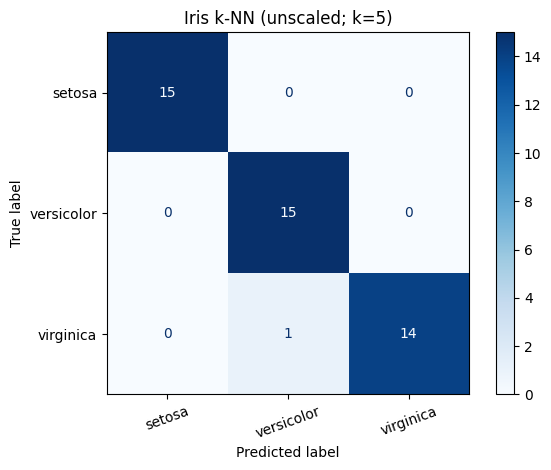

In [9]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    stratify=y, random_state=42)
print('Iris samples:', X.shape, '| train:', len(y_train), '| test:', len(y_test))
print('Class order:', list(iris.target_names))

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
results = []
models = {}
for k in [1,3,5,7]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    pred = m.predict(X_test)
    results.append({'k':k, 'test_accuracy':accuracy_score(y_test,pred)})
    models[k] = m
table = pd.DataFrame(results)
print(table.to_string(index=False))
best_k = sorted(results, key=lambda d: (-d['test_accuracy'],d['k']))[0]['k']
best_pred = models[best_k].predict(X_test)
print(f'Best k on this fixed test split: {best_k}')
print('Confusion matrix (rows=true, columns=predicted):\n', confusion_matrix(y_test,best_pred))
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
scaled_knn.fit(X_train, y_train)
scaled_pred = scaled_knn.predict(X_test)
print('Unscaled accuracy:', round(accuracy_score(y_test,best_pred),4))
print('Scaled accuracy:', round(accuracy_score(y_test,scaled_pred),4))
print('Scaled confusion matrix:\n', confusion_matrix(y_test,scaled_pred))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=iris.target_names,
                                        cmap='Blues', xticks_rotation=20)
plt.title(f'Iris k-NN (unscaled; k={best_k})'); plt.tight_layout(); plt.show()


### Result interpretation and discussion
Standardization changes the relative influence of features when their numerical scales differ. Using a `Pipeline` ensures the scaler is fitted on training data only. **Coursework note:** Selecting the best $k$ directly on the test set follows the exam instruction, but in a real ML study, tune $k$ on a separate validation set or inner CV, reserving the test set for one final unbiased evaluation.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is an intelligent agent? | A system that perceives its environment and selects actions. |
| What does PEAS stand for? | Performance, Environment, Actuators, Sensors. |
| Why BFS uses a queue? | FIFO yields shallowest-first expansion in an unweighted graph. |
| How does Greedy select the next node? | It chooses minimum heuristic $h(n)$. |
| What is $k$ in k-NN? | Number of nearest training samples considered. |
| Why scale features? | So large-unit features do not automatically dominate distance. |
| What is a confusion matrix? | Counts of true versus predicted classes. |

| What is the main difference between BFS and DFS? | BFS uses a FIFO queue and explores level by level; DFS uses a stack or recursion and goes deep first. |
| What is a heuristic function? | h(n) estimates the remaining cost or distance from node n to the goal. |
| Give one PEAS example for a university delivery robot. | Performance: timely safe delivery; Environment: campus halls; Actuators: wheels and gripper; Sensors: camera and proximity sensor. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 02 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Forward chaining with Cold | 25 |
| Q2 | Depth-limited search and IDDFS | 30 |
| Q3 | Simple linear regression | 35 |
| Q4 | Viva: facts/rules, cutoff, slope, R² | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_02/Set_02_A.py) | [Q2 / B](Set_02/Set_02_B.py) | [Q3 / C](Set_02/Set_02_C.py) | [Q4 / D: Viva practice](Set_02/Set_02_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Knowledge-Based Agent (25 marks)
**Question specification**  
`Cloudy`; `Cloudy→Rain`; `Rain→WetGround`; `WetGround→Slippery`; `Slippery→DriveSlowly`; `Rain AND Cold→WearJacket`. Run forward chaining without Cold and with Cold. Print initial facts, rules fired, final knowledge, and explain `WearJacket`.

### Theory and mathematical background
A knowledge base (KB) stores **facts** and **rules**. In propositional forward chaining, rules have premises and a conclusion. For example:
$$P\land Q\Rightarrow R.$$
A rule fires when all its premises are already known. This is repeated until no new conclusion can be inferred (the *fixed point*).

For implication, $P\Rightarrow Q\equiv \neg P\lor Q$; it is false only when $P$ is true and $Q$ is false. Forward chaining for definite Horn-style rules is a data-driven form of logical inference.

In [4]:

def forward_chain(initial_facts, rules):
    """Data-driven inference: rules are (premise-set, conclusion) pairs."""
    known = set(initial_facts)
    trace = []
    while True:
        newly_added = False
        for premises, conclusion in rules:
            if premises.issubset(known) and conclusion not in known:
                known.add(conclusion)
                trace.append((sorted(premises), conclusion))
                newly_added = True
        if not newly_added:
            break
    return known, trace

def print_inference(label, initial, rules):
    known, trace = forward_chain(initial, rules)
    print(f"\n{label} | Initial facts: {sorted(initial)}")
    for i, (prem, conclusion) in enumerate(trace, 1):
        print(f"  {i}. {prem}  =>  {conclusion}")
    if not trace: print("  No new rule fired.")
    print('Final facts:', sorted(known))
    return known, trace

rules = [({'Cloudy'},'Rain'), ({'Rain'},'WetGround'),
         ({'WetGround'},'Slippery'), ({'Slippery'},'DriveSlowly'),
         ({'Rain','Cold'},'WearJacket')]
no_cold, t1 = print_inference('Case A: without Cold', {'Cloudy'}, rules)
with_cold, t2 = print_inference('Case B: with Cold', {'Cloudy','Cold'}, rules)
print('WearJacket without Cold?', 'WearJacket' in no_cold)
print('WearJacket with Cold?', 'WearJacket' in with_cold)
assert 'WearJacket' not in no_cold and 'WearJacket' in with_cold



Case A: without Cold | Initial facts: ['Cloudy']
  1. ['Cloudy']  =>  Rain
  2. ['Rain']  =>  WetGround
  3. ['WetGround']  =>  Slippery
  4. ['Slippery']  =>  DriveSlowly
Final facts: ['Cloudy', 'DriveSlowly', 'Rain', 'Slippery', 'WetGround']

Case B: with Cold | Initial facts: ['Cloudy', 'Cold']
  1. ['Cloudy']  =>  Rain
  2. ['Rain']  =>  WetGround
  3. ['WetGround']  =>  Slippery
  4. ['Slippery']  =>  DriveSlowly
  5. ['Cold', 'Rain']  =>  WearJacket
Final facts: ['Cloudy', 'Cold', 'DriveSlowly', 'Rain', 'Slippery', 'WearJacket', 'WetGround']
WearJacket without Cold? False
WearJacket with Cold? True


### Result interpretation and discussion
In the first run, `Rain` becomes known but `Cold` is not known, so the **conjunctive** rule does not fire. With `Cold` asserted, both premises are available and `WearJacket` is derived. Absence from a knowledge base is not automatically logical negation (open-world caution).

---
## Q2. Depth-Limited and Iterative-Deepening Search (30 marks)
**Question specification**  
`S→{A,B}, A→{C,D}, B→{E,F}, C→{H}, D→{G}, E→{I}, F→{J}`. Search S to G using DLS limits 2 and 3 and IDDFS; show trace, cutoff, and repeated shallow search.

### Theory and mathematical background
**Depth-Limited Search (DLS)** stops descending beyond an allowed depth $\ell$. A depth cutoff means the search might succeed with a larger limit; *failure* means no answer was found without such a cutoff.

**Iterative Deepening DFS (IDDFS)** performs DLS repeatedly at limits $0,1,2,\ldots$ until a goal is found:
$$IDDFS(\ell)=DLS(0),DLS(1),\dots,DLS(\ell).$$
It revisits shallow nodes, trading some repeated time for the memory efficiency of depth-first search. In a tree, DLS is commonly characterized by $O(b^\ell)$ time and $O(b\ell)$ space when sibling iterators are retained; IDDFS has roughly $O(b^d)$ time and $O(bd)$ space for a finite branching factor.

In [5]:
def depth_limited_search(graph, start, goal, limit):
    """Return path, status (success/cutoff/failure), expanded sequence."""
    expanded = []
    def visit(node, path, depth):
        expanded.append((node, depth))
        if node == goal: return path, 'success'
        if depth >= limit:
            eligible = [v for v in graph.get(node, []) if v not in path]
            return None, ('cutoff' if eligible else 'failure')
        had_cutoff = False
        for nxt in graph.get(node, []):
            if nxt in path: continue
            result, status = visit(nxt, path + [nxt], depth + 1)
            if status == 'success': return result, status
            if status == 'cutoff': had_cutoff = True
        return None, 'cutoff' if had_cutoff else 'failure'
    path, status = visit(start, [start], 0)
    return path, status, expanded

def iddfs(graph, start, goal, max_depth=10):
    iterations = []
    for limit in range(max_depth+1):
        path, status, expanded = depth_limited_search(graph, start, goal, limit)
        iterations.append((limit, path, status, expanded))
        if status == 'success': break
        if status == 'failure': break
    return path, iterations

def print_iddfs(graph, start, goal, max_depth=10):
    path, iterations = iddfs(graph, start, goal, max_depth)
    for limit, candidate, status, expanded in iterations:
        trace = ' -> '.join(node for node, depth in expanded)
        print(f'Limit={limit} | status={status:7} | expanded={trace} | path={candidate}')
    print(f'IDDFS path: {path}; root visits: {len(iterations)}')
    return path, iterations

graph = {'S':['A','B'],'A':['C','D'],'B':['E','F'],
         'C':['H'],'D':['G'],'E':['I'],'F':['J'],
         'G':[],'H':[],'I':[],'J':[]}
for limit in [2,3]:
    path,status,expanded = depth_limited_search(graph,'S','G',limit)
    print(f'DLS {limit}: status={status}; path={path}; expanded={expanded}')
path, iterations = print_iddfs(graph,'S','G',6)
assert path == ['S','A','D','G']


DLS 2: status=cutoff; path=None; expanded=[('S', 0), ('A', 1), ('C', 2), ('D', 2), ('B', 1), ('E', 2), ('F', 2)]
DLS 3: status=success; path=['S', 'A', 'D', 'G']; expanded=[('S', 0), ('A', 1), ('C', 2), ('H', 3), ('D', 2), ('G', 3)]
Limit=0 | status=cutoff  | expanded=S | path=None
Limit=1 | status=cutoff  | expanded=S -> A -> B | path=None
Limit=2 | status=cutoff  | expanded=S -> A -> C -> D -> B -> E -> F | path=None
Limit=3 | status=success | expanded=S -> A -> C -> H -> D -> G | path=['S', 'A', 'D', 'G']
IDDFS path: ['S', 'A', 'D', 'G']; root visits: 4


### Result interpretation and discussion
The goal is at depth 3 (`S→A→D→G`), so the limit-2 run is cut off before that node; limit 3 succeeds. IDDFS repeats nodes near the root in each iteration but needs memory proportional to depth rather than the breadth of the entire frontier.

---
## Q3. Linear Regression (35 marks)
**Question specification**  
Fit simple linear regression to `(1,4),(2,5),(3,8),(4,9),(5,11),(6,14)`; report slope, intercept, prediction at 7 hours, $R^2$, and plot. Change the score at 6 hours from 14 to 18 and refit.

### Theory and mathematical background
Simple linear regression estimates a numerical response from a predictor:
$$\hat y_i=\beta_0+\beta_1x_i.$$
The least-squares estimator minimizes
$$SSE=\sum_{i=1}^{n}\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)^2,$$
with $\hat\beta_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}$ and $\hat\beta_0=\bar y-\hat\beta_1\bar x$.

The coefficient of determination is
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
An in-sample $R^2$ measures fit to the data used; test $R^2$ estimates performance on unseen data. With small test sets, the latter can be unstable or negative.

Original: slope=1.9714; intercept=1.6000; pred(7)=15.4000; train R²=0.9786
Modified last score: slope=2.5429; intercept=0.2667; pred(7)=18.0667; train R²=0.8922


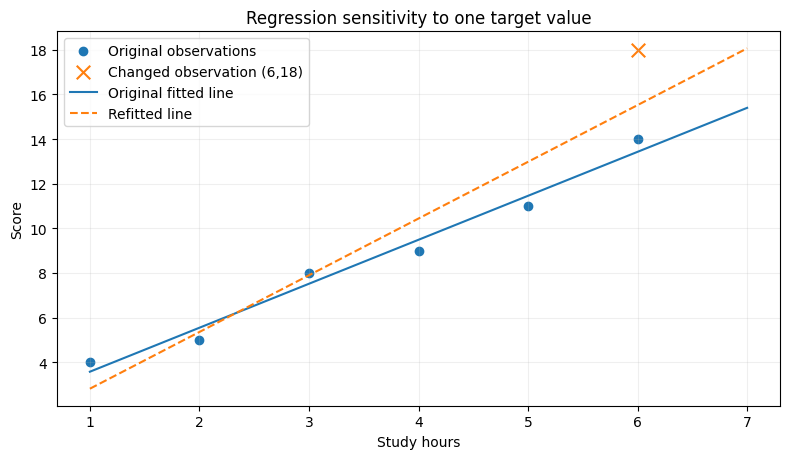

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
X = np.array([1,2,3,4,5,6],dtype=float).reshape(-1,1)
y = np.array([4,5,8,9,11,14],dtype=float)
model = LinearRegression().fit(X,y)
y_changed = y.copy(); y_changed[-1] = 18
changed_model = LinearRegression().fit(X,y_changed)
for label, mdl, target in [('Original',model,y),('Modified last score',changed_model,y_changed)]:
    print(f'{label}: slope={mdl.coef_[0]:.4f}; intercept={mdl.intercept_:.4f}; '
          f'pred(7)={mdl.predict([[7]])[0]:.4f}; train R²={mdl.score(X,target):.4f}')
grid = np.linspace(1,7,80).reshape(-1,1)
plt.figure(figsize=(8,4.7))
plt.scatter(X[:,0],y,label='Original observations')
plt.scatter([6],[18],marker='x',s=95,label='Changed observation (6,18)')
plt.plot(grid[:,0],model.predict(grid),label='Original fitted line')
plt.plot(grid[:,0],changed_model.predict(grid),'--',label='Refitted line')
plt.xlabel('Study hours'); plt.ylabel('Score'); plt.title('Regression sensitivity to one target value')
plt.grid(alpha=0.2); plt.legend(); plt.tight_layout(); plt.show()


### Result interpretation and discussion
Increasing the last score changes both the least-squares slope/intercept and residual structure, so $R^2$ need not increase. With only six observations, a single changed point can strongly affect a fitted line; avoid interpreting the relationship as causal. Here $R^2$ is **training** performance only.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is forward chaining? | Repeated application of satisfied rules to asserted facts. |
| What is a knowledge base? | A set of encoded facts and rules. |
| What is cutoff? | Search reaches the specified limit before ruling out deeper goals. |
| Why IDDFS revisits the root? | It restarts DLS with an incremented limit. |
| What is regression slope? | Expected change in predicted response for a one-unit predictor change. |
| What is the intercept? | Predicted response at input zero. |
| What does R² measure? | Goodness of fit relative to predicting the response mean. |

| How is a fact different from a rule? | A fact is currently known, such as Cloudy. A rule is an implication such as Cloudy implies Rain. |
| What is depth-limited search (DLS)? | A depth-first search that does not expand any node beyond a specified depth limit. |
| What is IDDFS? | Iterative Deepening Depth-First Search runs DLS at increasing limits until a goal is found. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 03 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | First-order parent relations | 25 |
| Q2 | A* with an admissible heuristic | 30 |
| Q3 | Iris K-means model selection | 35 |
| Q4 | Viva: FOL, g/h/f, centroid, inertia, silhouette | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_03/Set_03_A.py) | [Q2 / B](Set_03/Set_03_B.py) | [Q3 / C](Set_03/Set_03_C.py) | [Q4 / D: Viva practice](Set_03/Set_03_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. First-Order Logic Representation (25 marks)
**Question specification**  
Given `Parent(Ali,Babu)`, `Parent(Ali,Rina)`, `Parent(Babu,Karim)`, `Parent(Rina,Sumi)`, `Parent(Karim,Nila)`, implement children, grandparent, and sibling queries, and display inferred relations.

### Theory and mathematical background
First-order logic models named **objects** and **relations**. For instance, $Parent(Ali,Babu)$ asserts a binary relation; `Ali` and `Babu` are constants, whereas $x,y,z$ are variables.

A grandparent inference rule is
$$\forall x\,\forall y\,\forall z:\quad Parent(x,y)\land Parent(y,z)\Rightarrow Grandparent(x,z).$$
A sibling relation uses a shared parent:
$$Sibling(x,y)\Leftarrow\exists p\, [Parent(p,x)\land Parent(p,y)\land x\ne y].$$
The implementation below demonstrates **specific relation inference over Python tuples**, not a general-purpose first-order theorem prover.

In [1]:
from itertools import combinations

def children_of(person, parents):
    return sorted({child for parent, child in parents if parent == person})

def grandparent_relations(parents):
    return sorted({(x, z) for x, y in parents for middle, z in parents if y == middle})

def siblings_relations(parents):
    result = set()
    for p in {person for person, child in parents}:
        children = children_of(p, parents)
        for x, y in combinations(children, 2):
            result.add((x, y))  # Canonical unordered pair: no duplicates/self-pairs.
    return sorted(result)

def print_relations(parents):
    people = sorted({x for pair in parents for x in pair})
    print('Parent facts:', sorted(parents))
    print('Children queries:')
    for name in people:
        kids = children_of(name, parents)
        if kids: print(f'  children_of({name}) = {kids}')
    print('Grandparent relations:', grandparent_relations(parents))
    print('Sibling relations (unordered):', siblings_relations(parents))

parents = {('Ali','Babu'),('Ali','Rina'),('Babu','Karim'),
           ('Rina','Sumi'),('Karim','Nila')}
print_relations(parents)
print('Example binding: Parent(Ali,Babu) and Parent(Babu,Karim) => Grandparent(Ali,Karim)')
assert ('Ali','Karim') in grandparent_relations(parents)
assert ('Babu','Rina') in siblings_relations(parents)


Parent facts: [('Ali', 'Babu'), ('Ali', 'Rina'), ('Babu', 'Karim'), ('Karim', 'Nila'), ('Rina', 'Sumi')]
Children queries:
  children_of(Ali) = ['Babu', 'Rina']
  children_of(Babu) = ['Karim']
  children_of(Karim) = ['Nila']
  children_of(Rina) = ['Sumi']
Grandparent relations: [('Ali', 'Karim'), ('Ali', 'Sumi'), ('Babu', 'Nila')]
Sibling relations (unordered): [('Babu', 'Rina')]
Example binding: Parent(Ali,Babu) and Parent(Babu,Karim) => Grandparent(Ali,Karim)


### Result interpretation and discussion
Tuple matching binds a common intermediate value $y$ in `Parent(x,y)` and `Parent(y,z)`. Siblings are printed as **unordered pairs** and exclude self-pairs. For example, `Babu` and `Rina` share parent `Ali`.

---
## Q2. A* Search (30 marks)
**Question specification**  
Directed weighted edges: `S-A=2, S-B=4, A-C=2, A-D=5, B-D=1, C-G=5, D-G=3`; `h(S,A,B,C,D,G)=(6,5,4,4,2,0)`. Print expansion trace with $g,h,f$, best path and total cost; rerun with all $h=0$.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

graph={'S':[('A',2),('B',4)],'A':[('C',2),('D',5)],
       'B':[('D',1)],'C':[('G',5)],'D':[('G',3)],'G':[]}
h={'S':6,'A':5,'B':4,'C':4,'D':2,'G':0}
path,cost,trace=astar(graph,h,'S','G')
display_astar_trace(trace)
print('A* path:',path,'| total cost:',cost)
h_zero={node:0 for node in h}
zero_path,zero_cost,zero_trace=astar(graph,h_zero,'S','G')
print('With h=0 (uniform-cost behavior):',zero_path,'| cost:',zero_cost)
display_astar_trace(zero_trace)
assert cost == zero_cost


Node     g(n)     h(n)     f(n)
   S        0        6        6
   A        2        5        7
   B        4        4        8
   D        5        2        7
   C        4        4        8
   G        8        0        8
A* path: ['S', 'B', 'D', 'G'] | total cost: 8
With h=0 (uniform-cost behavior): ['S', 'B', 'D', 'G'] | cost: 8
Node     g(n)     h(n)     f(n)
   S        0        0        0
   A        2        0        2
   B        4        0        4
   C        4        0        4
   D        5        0        5
   G        8        0        8


### Result interpretation and discussion
With $h(n)=0$, the A* priority becomes $f(n)=g(n)$, so it behaves like uniform-cost search on nonnegative edge costs. The true optimal cost here is 8 via `S→B→D→G` (4+1+3). Equal-cost alternate routes are possible; the tie-breaker determines which one is returned.

---
## Q3. K-means Clustering (35 marks)
**Question specification**  
Use the **first two Iris features**. Compare $k=2,3,4,5$ using inertia and silhouette, select a suitable $k$, and visualize the cluster assignments and centroids.

### Theory and mathematical background
**K-means** is an unsupervised clustering method that alternates assigning samples to the nearest centroid and updating centroids. For $K$ clusters, it seeks to minimize
$$J=\sum_{i=1}^{n}\left\|\mathbf x_i-\boldsymbol\mu_{z_i}\right\|_2^2.$$
`inertia_` is the final within-cluster sum of squares. The silhouette of a sample is
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},$$
where $a(i)$ is average within-cluster distance and $b(i)$ is its smallest mean distance to another cluster. Larger silhouette generally indicates better-separated clusters. **Cluster IDs are arbitrary** and are not species class labels.

Feature scaling changes the distance geometry and inertia's units; compare inertia only for models using comparable feature representations.

 k  inertia  silhouette
 2  58.2041      0.4630
 3  37.0507      0.4451
 4  27.9902      0.4249
 5  20.9968      0.4101
Selected k (highest silhouette among tested values): 2
Centroids (sepal length, sepal width):
 [[5.224 3.131]
 [6.61  2.966]]


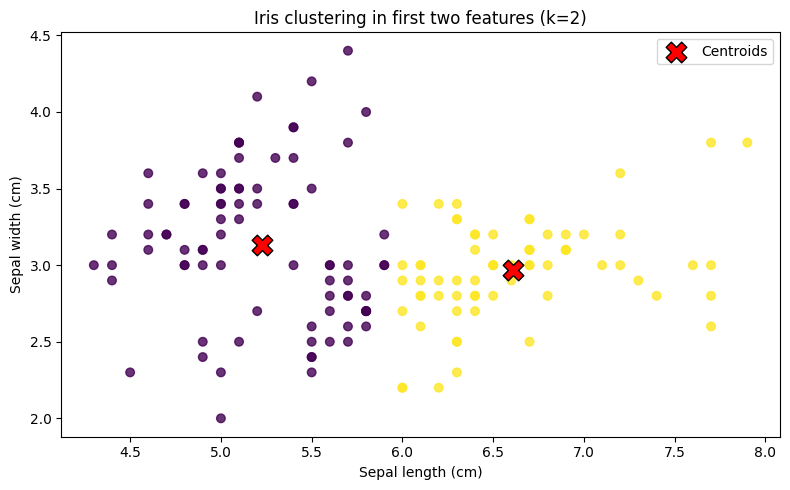

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()

X = iris.data[:, :2]  # sepal length and sepal width (cm)
rows, cluster_models = [], {}
for k in [2,3,4,5]:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    score = silhouette_score(X,model.labels_)
    rows.append({'k':k,'inertia':model.inertia_,'silhouette':score})
    cluster_models[k]=model
table=pd.DataFrame(rows)
print(table.round(4).to_string(index=False))
selected_k=int(table.loc[table['silhouette'].idxmax(),'k'])
best=cluster_models[selected_k]
print('Selected k (highest silhouette among tested values):',selected_k)
print('Centroids (sepal length, sepal width):\n',best.cluster_centers_.round(3))
plt.figure(figsize=(8,5))
plt.scatter(X[:,0],X[:,1],c=best.labels_,alpha=.8,s=38,cmap='viridis')
plt.scatter(best.cluster_centers_[:,0],best.cluster_centers_[:,1],
            marker='X',s=220,c='red',edgecolors='black',label='Centroids')
plt.xlabel('Sepal length (cm)'); plt.ylabel('Sepal width (cm)')
plt.title(f'Iris clustering in first two features (k={selected_k})')
plt.legend(); plt.tight_layout(); plt.show()


### Result interpretation and discussion
The chosen $k$ follows a **defined criterion** (largest silhouette of the four candidates); other justified criteria can select a different $k$. A cluster labeled 0 is merely the first centroid index returned by K-means and is **not** Iris species class 0.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is a predicate? | A relation/property symbol such as Parent(x,y). |
| What is tuple matching? | Binding the same intermediate object across relation facts. |
| What is g(n)? | Accumulated path cost from the start. |
| What is h(n)? | Estimated remaining goal cost. |
| What is f(n)? | A* priority: g(n)+h(n). |
| What is a centroid? | Mean feature vector of a cluster. |
| What is inertia? | Sum of squared distances to assigned centroids. |
| What is silhouette? | Cluster cohesion-versus-separation score. |

| What is a constant in first-order logic? | A symbol naming a specific object, such as Ali or Rina. |
| What is a variable in first-order logic? | A placeholder, such as x or y, that may refer to different objects. |
| What does admissible mean for h(n)? | The estimate never exceeds the actual least remaining cost to the goal. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 04 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | BFS/DFS/bidirectional search | 30 |
| Q2 | WEKA J48 and IBk cross-validation | 30 |
| Q3 | Linear regression and perturbation | 30 |
| Q4 | Viva: search, WEKA CV, IBk, regression | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_04/Set_04_A.py) | [Q2 / B](Set_04/Set_04_B.py) | [Q3 / C](Set_04/Set_04_C.py) | [Q4 / D: Viva practice](Set_04/Set_04_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Search Comparison (30 marks)
**Question specification**  
`P→{Q,R}, Q→{S,T}, R→{U}, S→{V}, T→{V}, U→{V}, V→{}`. Compare BFS, DFS, bidirectional search from P to V, showing path, expansion order, number expanded. Reverse the neighbor order of Q and rerun DFS.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

**Bidirectional search** grows frontiers from both ends. For a directed graph, the backward frontier must use **reversed edges**, otherwise it may report an invalid path.

In [1]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

from collections import deque

def bidirectional_search(graph, start, goal):
    """BFS forward on directed edges and backward on their reversed edges."""
    if start == goal: return [start], [('forward', start)]
    reverse = {u: [] for u in graph}
    for u, neighbors in graph.items():
        for v in neighbors:
            reverse.setdefault(v, []).append(u)
    f_queue, b_queue = deque([start]), deque([goal])
    forward_paths, backward_paths = {start:[start]}, {goal:[goal]}
    trace = []
    while f_queue and b_queue:
        for direction, queue, own, other, adjacency in [
            ('forward', f_queue, forward_paths, backward_paths, graph),
            ('backward', b_queue, backward_paths, forward_paths, reverse),
        ]:
            for _ in range(len(queue)):
                node = queue.popleft()
                trace.append((direction, node))
                if node in other:
                    return forward_paths[node] + backward_paths[node][1:], trace
                for nxt in adjacency.get(node, []):
                    if nxt in own: continue
                    own[nxt] = (own[node] + [nxt]) if direction == 'forward' else ([nxt] + own[node])
                    queue.append(nxt)
                    if nxt in other:
                        return forward_paths[nxt] + backward_paths[nxt][1:], trace
    return None, trace

graph={'P':['Q','R'],'Q':['S','T'],'R':['U'],'S':['V'],
       'T':['V'],'U':['V'],'V':[]}
for label, fn in [('BFS',bfs),('DFS',dfs)]:
    path, expanded = fn(graph,'P','V')
    print(f'{label}: path={path}; expanded={expanded}; expanded count={len(expanded)}')
bidir_path,bidir_trace=bidirectional_search(graph,'P','V')
print('Bidirectional:',bidir_path,'| expansion order (direction, node):',bidir_trace,
      '| expanded count:',len(bidir_trace))
changed={k:list(v) for k,v in graph.items()}
changed['Q']=list(reversed(changed['Q']))
print('DFS with Q children reversed:',dfs(changed,'P','V'))


BFS: path=['P', 'Q', 'S', 'V']; expanded=['P', 'Q', 'R', 'S', 'T', 'U', 'V']; expanded count=7
DFS: path=['P', 'Q', 'S', 'V']; expanded=['P', 'Q', 'S', 'V']; expanded count=4
Bidirectional: ['P', 'Q', 'S', 'V'] | expansion order (direction, node): [('forward', 'P'), ('backward', 'V'), ('forward', 'Q')] | expanded count: 3
DFS with Q children reversed: (['P', 'Q', 'T', 'V'], ['P', 'Q', 'T', 'V'])


### Result interpretation and discussion
Reversing Q’s adjacency from `[S,T]` to `[T,S]` changes **DFS branch ordering**; depending on how quickly the goal is found, the route or trace can change. Bidirectional expansions are counted as actual **dequeued** nodes in both directions; a meeting discovered during successor generation may not itself be dequeued.

---
## Q2. WEKA Classification (30 marks)
**Question specification**  
Using `iris.arff` in WEKA Explorer, inspect attributes and set the correct class. Run **J48** with 10-fold CV and **IBk** at $k=1,3,5$; record accuracy/confusion matrices, compare J48 to best IBk; save screenshots/result buffers.

### Theory and mathematical background
**WEKA Explorer** is a GUI workbench for data mining. In this experiment:
- `J48` is a C4.5-style decision-tree implementation.
- `IBk` is a nearest-neighbor classifier; the value of $k$ controls the number of neighbors.
- In **10-fold cross-validation**, the dataset is partitioned into ten folds. Each fold is evaluated once using a model trained on the remaining folds. A common summary is:
$$\mathrm{CV\ accuracy}=\frac{\text{total held-out correct predictions}}{\text{total held-out predictions}}.$$

A saved **WEKA result buffer** is required evidence: a Python evaluation of a similar method must not be presented as if it were the output of WEKA. To prevent preprocessing leakage, use WEKA's **FilteredClassifier** when evaluating scaling under cross-validation.

In [2]:
from pathlib import Path
from scipy.io import arff
from collections import Counter
# Use the same data file in a notebook and in a standalone Python script.
try:
    iris_path = Path(__file__).with_name("iris.arff")
except NameError:  # Jupyter notebooks do not define __file__.
    iris_path = Path("Set_04/iris.arff") if Path("Set_04/iris.arff").exists() else Path("iris.arff")
data,meta=arff.loadarff(iris_path)
classes=[s.decode('utf-8') for s in data['class']]
print('File:',iris_path.resolve())
print('WEKA attributes:',meta.names())
print('Instances:',len(data),'| class counts:',dict(Counter(classes)))
assert len(data)==150 and len(set(classes))==3
print("NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.")


File: /Users/macbookair/Desktop/Disk Sajjad/IU ICT 2020-21/Academic Files/4th Year 2nd Semester/ICT-4202 Artificial Intelligence and Machine Learning Laboratory/ICT-4202-AI-ML-Laboratory/Set_04/iris.arff
WEKA attributes: ['sepallength', 'sepalwidth', 'petallength', 'petalwidth', 'class']
Instances: 150 | class counts: {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}
NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.


### WEKA procedure (must be completed in WEKA)
1. Open **WEKA → Explorer → Preprocess → Open file → `iris.arff`** (provided in this set folder). Verify 150 instances and five attributes. Select `class` (the final, nominal attribute).
2. **Classify → Choose → `trees.J48` → Test options: Cross-validation, 10 folds → Start.** In the result list, right-click the run to view/copy the output buffer. Save an image of the confusion matrix.
3. Repeat in **Classify → `lazy.IBk`**, setting `KNN=1`, `KNN=3`, then `KNN=5`; retain the same 10-fold evaluation setup.
4. Record **Correctly Classified Instances (%), confusion matrix**, and optionally weighted F1. Compare the *measured* best IBk score to J48.

**Real WEKA results — fill after running the GUI**

| Classifier | k | 10-fold CV accuracy (%) | Confusion matrix / saved result |
|:--|--:|--:|:--|
| J48 | — | *run WEKA* | *attach real result buffer* |
| IBk | 1 | *run WEKA* | *attach real result buffer* |
| IBk | 3 | *run WEKA* | *attach real result buffer* |
| IBk | 5 | *run WEKA* | *attach real result buffer* |

**Why these results are blank:** WEKA is a separate Java application. The Python cell above only verifies the dataset; no WEKA performance figures are invented.

---
## Q3. Linear Regression (30 marks)
**Question specification**  
`X=[2,4,6,8,10,12]`, `Y=[5,9,13,17,21,25]`: fit regression, slope/intercept, predict at X=15, $R^2$, plot. Modify one target and explain effect.

### Theory and mathematical background
Simple linear regression estimates a numerical response from a predictor:
$$\hat y_i=\beta_0+\beta_1x_i.$$
The least-squares estimator minimizes
$$SSE=\sum_{i=1}^{n}\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)^2,$$
with $\hat\beta_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}$ and $\hat\beta_0=\bar y-\hat\beta_1\bar x$.

The coefficient of determination is
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
An in-sample $R^2$ measures fit to the data used; test $R^2$ estimates performance on unseen data. With small test sets, the latter can be unstable or negative.

Original: slope=2.0000; intercept=1.0000; prediction(15)=31.0000; R²=1.0000
Changed last y (25→30): slope=2.3571; intercept=-0.6667; R²=0.9703


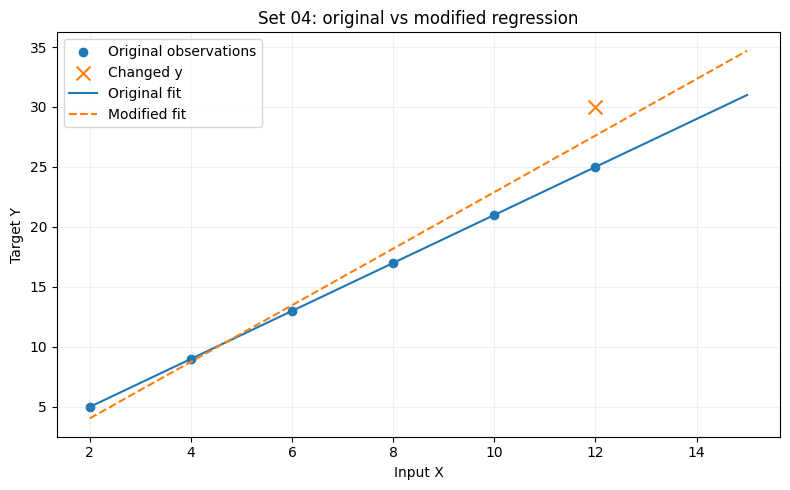

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
X=np.array([2,4,6,8,10,12],dtype=float).reshape(-1,1)
y=np.array([5,9,13,17,21,25],dtype=float)
fit=LinearRegression().fit(X,y)
print(f'Original: slope={fit.coef_[0]:.4f}; intercept={fit.intercept_:.4f}; '
      f'prediction(15)={fit.predict([[15]])[0]:.4f}; R²={fit.score(X,y):.4f}')
y_mod=y.copy(); y_mod[-1]=30  # Illustrative modification (question leaves value unspecified).
fit_mod=LinearRegression().fit(X,y_mod)
print(f'Changed last y (25→30): slope={fit_mod.coef_[0]:.4f}; '
      f'intercept={fit_mod.intercept_:.4f}; R²={fit_mod.score(X,y_mod):.4f}')
grid=np.linspace(2,15,80).reshape(-1,1)
plt.figure(figsize=(8,5))
plt.scatter(X[:,0],y,label='Original observations');plt.scatter([12],[30],marker='x',s=100,label='Changed y')
plt.plot(grid[:,0],fit.predict(grid),label='Original fit')
plt.plot(grid[:,0],fit_mod.predict(grid),'--',label='Modified fit')
plt.xlabel('Input X');plt.ylabel('Target Y');plt.title('Set 04: original vs modified regression')
plt.grid(alpha=.2);plt.legend();plt.tight_layout();plt.show()


### Result interpretation and discussion
The original points follow the **exact** relation $y=2x+1$, so in-sample $R^2=1$. Changing the last target to 30 is an *explicit illustrative choice*; the refitted line and $R^2$ change because the new data are no longer perfectly collinear.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| BFS versus DFS? | BFS expands breadth first (minimum-edge path); DFS follows a deep branch first. |
| How to run backward search on directed edges? | Use the reverse adjacency graph. |
| What is 10-fold CV? | Ten held-out validations, each using nine folds for training. |
| What is J48? | WEKA decision tree learner based on C4.5. |
| What is IBk? | WEKA nearest-neighbor classifier. |
| What does a regression slope mean? | Predicted response change for one unit of input. |

| What is bidirectional search? | Search from both start and goal, looking for a meeting point between the two frontiers. |
| Why report expanded nodes? | Expanded-node counts let us compare the effort used by different search strategies. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 05 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Three-location cleaning agent | 25 |
| Q2 | Greedy versus A* weighted search | 30 |
| Q3 | Decision-tree depth comparison | 35 |
| Q4 | Viva: agents, heuristics, overfitting, precision/recall/F1 | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_05/Set_05_A.py) | [Q2 / B](Set_05/Set_05_B.py) | [Q3 / C](Set_05/Set_05_C.py) | [Q4 / D: Viva practice](Set_05/Set_05_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Intelligent Agent (25 marks)
**Question specification**  
Design cleaning agent for A, B, C (Clean/Dirty). Clean current room, otherwise move, and use NoOp when all clean. Print location, percept, action, and environment after each step. Give PEAS.

### Theory and mathematical background
An **agent** senses the environment and selects an **action** from the current percept. A simple reflex rule depends on the current percept only; the rule `Dirty → Suck` is a condition-action rule.

A two-room agent that **stops when every room is clean** needs information beyond a purely local percept (either global sensing or internal state). Therefore the terminating variant is *reflex-style cleaning with global-state access*, not a strictly percept-only reflex agent.

Let $s_t$ denote the current environment and $a_t$ the selected action. A policy chooses $a_t=\pi(s_t)$, and the transition is $s_{t+1}=T(s_t,a_t)$. For the cleaning goal:
$$\text{NoOp when }\bigwedge_{r\in\mathcal{R}}\operatorname{Clean}(r).$$

**PEAS** describes Performance, Environment, Actuators, and Sensors.

In [1]:
# The question does not set initial conditions: these are an explicit reproducible example.
environment={'A':'Dirty','B':'Clean','C':'Dirty'}
locations=['A','B','C']
location='A'
print('Initial state (illustrative):', environment,'| starting at',location)
for step in range(1,14):
    percept=(location,environment[location])
    if all(s=='Clean' for s in environment.values()): action='NoOp'
    elif environment[location]=='Dirty': action='Suck'
    else: action='MoveRight'  # Cyclic route A -> B -> C -> A
    if action=='Suck': environment[location]='Clean'
    elif action=='MoveRight': location=locations[(locations.index(location)+1)%3]
    print(f'{step:02d} | location={percept[0]} | percept={percept} | action={action:9} | after={environment}')
    if action=='NoOp': break
assert all(s=='Clean' for s in environment.values())


Initial state (illustrative): {'A': 'Dirty', 'B': 'Clean', 'C': 'Dirty'} | starting at A
01 | location=A | percept=('A', 'Dirty') | action=Suck      | after={'A': 'Clean', 'B': 'Clean', 'C': 'Dirty'}
02 | location=A | percept=('A', 'Clean') | action=MoveRight | after={'A': 'Clean', 'B': 'Clean', 'C': 'Dirty'}
03 | location=B | percept=('B', 'Clean') | action=MoveRight | after={'A': 'Clean', 'B': 'Clean', 'C': 'Dirty'}
04 | location=C | percept=('C', 'Dirty') | action=Suck      | after={'A': 'Clean', 'B': 'Clean', 'C': 'Clean'}
05 | location=C | percept=('C', 'Clean') | action=NoOp      | after={'A': 'Clean', 'B': 'Clean', 'C': 'Clean'}


### PEAS — three-room cleaning robot
| Component | This task |
|:--|:--|
| Performance | All rooms cleaned, few unnecessary moves, low energy use |
| Environment | Three connected rooms A, B, C; each can be dirty or clean |
| Actuators | Suction motor (`Suck`), locomotion (`MoveRight`), idle (`NoOp`) |
| Sensors | Current location, current room dirt sensor, full clean-state signal or internal memory |

This is a **reflex-style policy with global cleanliness access** to meet the stopping requirement; a strictly local simple-reflex agent cannot generally know that every other room is clean.

---
## Q2. Greedy and A* Search (30 marks)
**Question specification**  
Costs: `A-B=2, A-C=3, B-D=4, B-E=2, C-E=2, D-G=3, E-G=4`; h(A,B,C,D,E,G)=(6,5,4,2,3,0). Show Greedy and A* expanded order, route and cost; explain why h-only can fail.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def greedy_weighted(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, g, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append((node, g, h[node]))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(counter), g+weight, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

graph={'A':[('B',2),('C',3)],'B':[('D',4),('E',2)],
       'C':[('E',2)],'D':[('G',3)],'E':[('G',4)],'G':[]}
h={'A':6,'B':5,'C':4,'D':2,'E':3,'G':0}
greedy_path,greedy_cost,greedy_trace=greedy_weighted(graph,h,'A','G')
a_path,a_cost,a_trace=astar(graph,h,'A','G')
print('Greedy expanded (node,g,h):',greedy_trace,'| path:',greedy_path,'| cost:',greedy_cost)
print('A* expanded (node,g,h,f):',a_trace,'| path:',a_path,'| cost:',a_cost)
display_astar_trace(a_trace)
assert a_cost <= greedy_cost


Greedy expanded (node,g,h): [('A', 0, 6), ('C', 3, 4), ('E', 5, 3), ('G', 9, 0)] | path: ['A', 'C', 'E', 'G'] | cost: 9
A* expanded (node,g,h,f): [('A', 0, 6, 6), ('B', 2, 5, 7), ('C', 3, 4, 7), ('E', 4, 3, 7), ('D', 6, 2, 8), ('G', 8, 0, 8)] | path: ['A', 'B', 'E', 'G'] | cost: 8
Node     g(n)     h(n)     f(n)
   A        0        6        6
   B        2        5        7
   C        3        4        7
   E        4        3        7
   D        6        2        8
   G        8        0        8


### Result interpretation and discussion
Greedy chooses the next node by $h$ alone. In this graph, a path through B→D is tempting when D has a low heuristic, but the paid edge costs matter; A* weighs both. The $h$ values given in the question are used **unchanged**. A* optimum is verified by the accumulated cost, not the number of visited states.

---
## Q3. Decision Tree Classification (35 marks)
**Question specification**  
Use Iris stratified 70/30 split. Train Decision Trees with `max_depth=1,2,3,4,None`; show train/test accuracy, best model confusion matrix, precision, recall, F1, and discuss fit.

### Theory and mathematical background
A **decision tree** recursively chooses feature thresholds that reduce node impurity. One measure is Gini impurity:
$$Gini(D)=1-\sum_{c=1}^{K}p(c\mid D)^2.$$
Restricting `max_depth` reduces complexity but can cause underfitting; large or unrestricted depth can memorize training samples and overfit.

For each class, $Precision=\frac{TP}{TP+FP}$, $Recall=\frac{TP}{TP+FN}$, and $F_1=\frac{2PR}{P+R}$. Macro averages assign equal weight to every class.

Iris samples: (150, 4) | train: 105 | test: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


max_depth  train_acc  test_acc
        1     0.6667    0.6667
        2     0.9714    0.8889
        3     0.9810    0.9778
        4     0.9905    0.8889
     None     1.0000    0.9333
Best depth (on given holdout): 3
Confusion matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



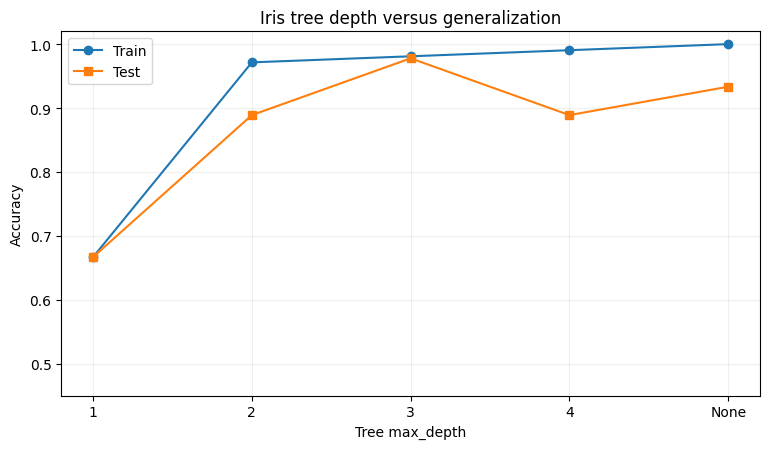

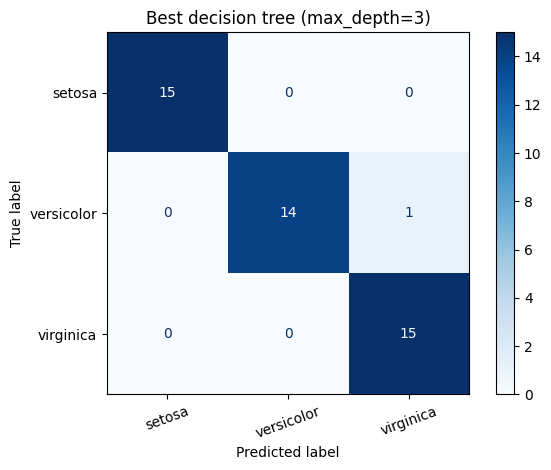

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    stratify=y, random_state=42)
print('Iris samples:', X.shape, '| train:', len(y_train), '| test:', len(y_test))
print('Class order:', list(iris.target_names))

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
scores, trained={},{ }
for depth in [1,2,3,4,None]:
    model=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
    scores[depth]=(model.score(X_train,y_train),model.score(X_test,y_test))
    trained[depth]=model
results=pd.DataFrame([{'max_depth':str(d),'train_acc':scores[d][0],
                       'test_acc':scores[d][1]} for d in [1,2,3,4,None]])
print(results.round(4).to_string(index=False))
# Deterministic ties: prefer the simplest depth, with unlimited last.
best_depth=max([1,2,3,4,None],key=lambda d:(scores[d][1],-({None:999}.get(d,d))))
best=trained[best_depth]
pred=best.predict(X_test)
print('Best depth (on given holdout):',best_depth)
print('Confusion matrix:\n',confusion_matrix(y_test,pred))
print(classification_report(y_test,pred,target_names=iris.target_names,zero_division=0))
depth_names=['1','2','3','4','None']
plt.figure(figsize=(7.8,4.6))
plt.plot(depth_names,results.train_acc,marker='o',label='Train')
plt.plot(depth_names,results.test_acc,marker='s',label='Test')
plt.xlabel('Tree max_depth');plt.ylabel('Accuracy');plt.ylim(0.45,1.02)
plt.title('Iris tree depth versus generalization');plt.grid(alpha=.2);plt.legend();plt.tight_layout();plt.show()
ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=iris.target_names,
                                        cmap='Blues',xticks_rotation=20)
plt.title(f'Best decision tree (max_depth={best_depth})');plt.tight_layout();plt.show()


### Result interpretation and discussion
Small depth is less flexible (possible **underfitting**). Large depth may achieve very high training accuracy yet no improvement in test accuracy (**overfitting risk**). For this lab, the question asks to compare on the test set; for a proper unbiased estimate, pick depth through cross-validation on training data, then evaluate the test set once.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Simple reflex agent? | Uses condition-action rules based on current percept only. |
| What is a state? | Current representation of the environment/problem. |
| Greedy versus A*? | Greedy minimizes h; A* minimizes g+h. |
| What is a tree split? | A feature-and-threshold test dividing samples. |
| Underfitting? | Model too simple to learn relevant patterns. |
| Overfitting? | Model fits training details/noise and generalizes poorly. |
| Precision/Recall/F1? | Precision: TP/(TP+FP); recall: TP/(TP+FN); F1: harmonic mean. |

| Why is Greedy not always optimal? | It considers h(n) only and can ignore the cost already paid, g(n). |
| Why compare training and test accuracy? | A large training-test performance gap can indicate overfitting. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 06 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Student eligibility using forward chaining | 25 |
| Q2 | BFS, DFS and IDDFS | 30 |
| Q3 | k-NN versus decision tree | 35 |
| Q4 | Viva: logic, implication, BFS/DFS/IDDFS, classification | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_06/Set_06_A.py) | [Q2 / B](Set_06/Set_06_B.py) | [Q3 / C](Set_06/Set_06_C.py) | [Q4 / D: Viva practice](Set_06/Set_06_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Propositional Logic (25 marks)
**Question specification**  
`Registered`; `Registered→Student`; `Student→HasID`; `Student AND PaidFee→ExamEligible`; `ExamEligible→CanEnterExamHall`. Infer for Registered alone and Registered + PaidFee, display traces, and construct implication truth table.

### Theory and mathematical background
A knowledge base (KB) stores **facts** and **rules**. In propositional forward chaining, rules have premises and a conclusion. For example:
$$P\land Q\Rightarrow R.$$
A rule fires when all its premises are already known. This is repeated until no new conclusion can be inferred (the *fixed point*).

For implication, $P\Rightarrow Q\equiv \neg P\lor Q$; it is false only when $P$ is true and $Q$ is false. Forward chaining for definite Horn-style rules is a data-driven form of logical inference.

In [1]:

def forward_chain(initial_facts, rules):
    """Data-driven inference: rules are (premise-set, conclusion) pairs."""
    known = set(initial_facts)
    trace = []
    while True:
        newly_added = False
        for premises, conclusion in rules:
            if premises.issubset(known) and conclusion not in known:
                known.add(conclusion)
                trace.append((sorted(premises), conclusion))
                newly_added = True
        if not newly_added:
            break
    return known, trace

def print_inference(label, initial, rules):
    known, trace = forward_chain(initial, rules)
    print(f"\n{label} | Initial facts: {sorted(initial)}")
    for i, (prem, conclusion) in enumerate(trace, 1):
        print(f"  {i}. {prem}  =>  {conclusion}")
    if not trace: print("  No new rule fired.")
    print('Final facts:', sorted(known))
    return known, trace

rules = [({'Registered'},'Student'),({'Student'},'HasID'),
         ({'Student','PaidFee'},'ExamEligible'),
         ({'ExamEligible'},'CanEnterExamHall')]
facts1,trace1=print_inference('Case 1: Registered only',{'Registered'},rules)
facts2,trace2=print_inference('Case 2: Registered + PaidFee',{'Registered','PaidFee'},rules)
assert 'CanEnterExamHall' not in facts1 and 'CanEnterExamHall' in facts2

import itertools
print('  P      Q      P -> Q')
for p, q in itertools.product([False, True], repeat=2):
    implication = (not p) or q
    print(f'{str(p):5}  {str(q):5}  {implication}')



Case 1: Registered only | Initial facts: ['Registered']
  1. ['Registered']  =>  Student
  2. ['Student']  =>  HasID
Final facts: ['HasID', 'Registered', 'Student']

Case 2: Registered + PaidFee | Initial facts: ['PaidFee', 'Registered']
  1. ['Registered']  =>  Student
  2. ['Student']  =>  HasID
  3. ['PaidFee', 'Student']  =>  ExamEligible
  4. ['ExamEligible']  =>  CanEnterExamHall
Final facts: ['CanEnterExamHall', 'ExamEligible', 'HasID', 'PaidFee', 'Registered', 'Student']
  P      Q      P -> Q
False  False  True
False  True   True
True   False  False
True   True   True


### Truth table: implication $P\Rightarrow Q$  
Recall: only **True → False** makes the implication false.

### Result interpretation and discussion
Eligibility is not inferred until the **conjunction** of `Student` and `PaidFee` is satisfied. That rule adds `ExamEligible`, enabling the downstream `CanEnterExamHall` conclusion. Forward chaining stops once a complete scan produces no additional fact.

---
## Q2. BFS, DFS and IDDFS (30 marks)
**Question specification**  
`S→{A,B}, A→{C,D}, B→{E,F}, C→{G}, D→{H}, E→{I}, F→{J}`. Search S to G using BFS, DFS and IDDFS. Show paths, nodes expanded, and memory behavior.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

**Depth-Limited Search (DLS)** stops descending beyond an allowed depth $\ell$. A depth cutoff means the search might succeed with a larger limit; *failure* means no answer was found without such a cutoff.

**Iterative Deepening DFS (IDDFS)** performs DLS repeatedly at limits $0,1,2,\ldots$ until a goal is found:
$$IDDFS(\ell)=DLS(0),DLS(1),\dots,DLS(\ell).$$
It revisits shallow nodes, trading some repeated time for the memory efficiency of depth-first search. In a tree, DLS is commonly characterized by $O(b^\ell)$ time and $O(b\ell)$ space when sibling iterators are retained; IDDFS has roughly $O(b^d)$ time and $O(bd)$ space for a finite branching factor.

In [2]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

def depth_limited_search(graph, start, goal, limit):
    """Return path, status (success/cutoff/failure), expanded sequence."""
    expanded = []
    def visit(node, path, depth):
        expanded.append((node, depth))
        if node == goal: return path, 'success'
        if depth >= limit:
            eligible = [v for v in graph.get(node, []) if v not in path]
            return None, ('cutoff' if eligible else 'failure')
        had_cutoff = False
        for nxt in graph.get(node, []):
            if nxt in path: continue
            result, status = visit(nxt, path + [nxt], depth + 1)
            if status == 'success': return result, status
            if status == 'cutoff': had_cutoff = True
        return None, 'cutoff' if had_cutoff else 'failure'
    path, status = visit(start, [start], 0)
    return path, status, expanded

def iddfs(graph, start, goal, max_depth=10):
    iterations = []
    for limit in range(max_depth+1):
        path, status, expanded = depth_limited_search(graph, start, goal, limit)
        iterations.append((limit, path, status, expanded))
        if status == 'success': break
        if status == 'failure': break
    return path, iterations

def print_iddfs(graph, start, goal, max_depth=10):
    path, iterations = iddfs(graph, start, goal, max_depth)
    for limit, candidate, status, expanded in iterations:
        trace = ' -> '.join(node for node, depth in expanded)
        print(f'Limit={limit} | status={status:7} | expanded={trace} | path={candidate}')
    print(f'IDDFS path: {path}; root visits: {len(iterations)}')
    return path, iterations

graph={'S':['A','B'],'A':['C','D'],'B':['E','F'],'C':['G'],
       'D':['H'],'E':['I'],'F':['J'],'G':[],'H':[],'I':[],'J':[]}
for name, fn in [('BFS',bfs),('DFS',dfs)]:
    path,trace=fn(graph,'S','G')
    print(f'{name}: path={path}; expanded={trace}; count={len(trace)}')
path,iterations=print_iddfs(graph,'S','G',8)
assert path==['S','A','C','G']


BFS: path=['S', 'A', 'C', 'G']; expanded=['S', 'A', 'B', 'C', 'D', 'E', 'F', 'G']; count=8
DFS: path=['S', 'A', 'C', 'G']; expanded=['S', 'A', 'C', 'G']; count=4
Limit=0 | status=cutoff  | expanded=S | path=None
Limit=1 | status=cutoff  | expanded=S -> A -> B | path=None
Limit=2 | status=cutoff  | expanded=S -> A -> C -> D -> B -> E -> F | path=None
Limit=3 | status=success | expanded=S -> A -> C -> G | path=['S', 'A', 'C', 'G']
IDDFS path: ['S', 'A', 'C', 'G']; root visits: 4


### Result interpretation and discussion
The goal is reached at depth 3. BFS uses a queue and stores potentially broad frontiers. DFS stores a narrower depth-oriented frontier but can wander deeply. IDDFS repeats the shallow levels but returns a shallowest-depth solution under finite branching.

---
## Q3. k-NN vs Decision Tree (35 marks)
**Question specification**  
Same stratified 70/30 Iris split for k-NN $k=5$ and a decision tree `max_depth=3`. Print both accuracies/confusion matrices, identify incorrect samples, standardize and repeat k-NN.

### Theory and mathematical background
**k-Nearest Neighbors (k-NN)** predicts the majority label among the $k$ nearest training samples. A common distance is Euclidean:
$$d(\mathbf x,\mathbf z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$
Standardization rescales a feature using training-set statistics:
$$z_j=\frac{x_j-\mu_j^{\mathrm{train}}}{\sigma_j^{\mathrm{train}}}.$$
**Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$ for binary labels (or total correct / total cases for multiclass). A confusion matrix $C_{ij}$ counts instances of actual class $i$ predicted as class $j$. Fit scaling on training samples only to prevent leakage.

A **decision tree** recursively chooses feature thresholds that reduce node impurity. One measure is Gini impurity:
$$Gini(D)=1-\sum_{c=1}^{K}p(c\mid D)^2.$$
Restricting `max_depth` reduces complexity but can cause underfitting; large or unrestricted depth can memorize training samples and overfit.

For each class, $Precision=\frac{TP}{TP+FP}$, $Recall=\frac{TP}{TP+FN}$, and $F_1=\frac{2PR}{P+R}$. Macro averages assign equal weight to every class.

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    stratify=y, random_state=42)
print('Iris samples:', X.shape, '| train:', len(y_train), '| test:', len(y_test))
print('Class order:', list(iris.target_names))

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train,y_train)
dt = DecisionTreeClassifier(max_depth=3,random_state=42).fit(X_train,y_train)
for name, model in [('k-NN (k=5)',knn),('Decision tree (depth=3)',dt)]:
    preds=model.predict(X_test)
    errors=np.flatnonzero(preds!=y_test)
    print(f'\n{name}: accuracy={accuracy_score(y_test,preds):.4f}')
    print('Confusion matrix (actual rows):\n',confusion_matrix(y_test,preds))
    print('Misclassified TEST ROW POSITIONS:',errors.tolist())
    for idx in errors[:10]:
        print(' ',idx, 'true:',iris.target_names[y_test[idx]],
              'predicted:',iris.target_names[preds[idx]],
              'features:',np.round(X_test[idx],2).tolist())
scaled_knn=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))
scaled_knn.fit(X_train,y_train)
scaled_pred=scaled_knn.predict(X_test)
print('\nScaled k-NN accuracy:',round(accuracy_score(y_test,scaled_pred),4))
print('Scaled confusion matrix:\n',confusion_matrix(y_test,scaled_pred))


Iris samples: (150, 4) | train: 105 | test: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

k-NN (k=5): accuracy=0.9778
Confusion matrix (actual rows):
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
Misclassified TEST ROW POSITIONS: [42]
  42 true: virginica predicted: versicolor features: [4.9, 2.5, 4.5, 1.7]

Decision tree (depth=3): accuracy=0.9778
Confusion matrix (actual rows):
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
Misclassified TEST ROW POSITIONS: [39]
  39 true: versicolor predicted: virginica features: [6.7, 3.0, 5.0, 1.7]

Scaled k-NN accuracy: 0.9111
Scaled confusion matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]


### Result interpretation and discussion
Distance-based k-NN is sensitive to feature units because feature scaling changes Euclidean distances and potentially neighbor ranks. Decision trees split on individual feature thresholds and are mostly invariant to positive linear rescaling. The train/test split remains identical for fair comparison.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Forward chaining? | Infer consequences repeatedly from satisfied premises. |
| When is P→Q false? | When P is true but Q is false. |
| What is a BFS frontier? | Queue of discovered paths/nodes awaiting expansion. |
| Why IDDFS uses less memory than BFS? | It performs depth-limited DFS rather than storing a full breadth frontier. |
| How k-NN works? | Votes among the k closest training instances. |
| Why standardize k-NN inputs? | To reduce unit-driven dominance in distances. |
| Decision tree? | Predicts via learned nested feature thresholds. |

| Which data structure does DFS use? | A LIFO stack, or the program call stack in recursive DFS. |
| How does IDDFS combine BFS and DFS benefits? | It finds a shallow goal by trying larger limits while retaining depth-first memory use. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 07 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Family FOL knowledge representation | 25 |
| Q2 | Greedy best-first heuristic sensitivity | 30 |
| Q3 | K-means with standardization | 35 |
| Q4 | Viva: relations, heuristics, scaling, silhouette | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_07/Set_07_A.py) | [Q2 / B](Set_07/Set_07_B.py) | [Q3 / C](Set_07/Set_07_C.py) | [Q4 / D: Viva practice](Set_07/Set_07_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. FOL and Knowledge Representation (25 marks)
**Question specification**  
`Parent(Rahman,Hasan)`, `Parent(Rahman,Nabila)`, `Parent(Hasan,Rafi)`, `Parent(Nabila,Tania)`, `Parent(Rafi,Samia)`. Implement `children_of(x)`, `grandchildren_of(x)`, `grandparent(x,z)` and `siblings(x,y)` avoiding duplicates/self-siblings.

### Theory and mathematical background
First-order logic models named **objects** and **relations**. For instance, $Parent(Ali,Babu)$ asserts a binary relation; `Ali` and `Babu` are constants, whereas $x,y,z$ are variables.

A grandparent inference rule is
$$\forall x\,\forall y\,\forall z:\quad Parent(x,y)\land Parent(y,z)\Rightarrow Grandparent(x,z).$$
A sibling relation uses a shared parent:
$$Sibling(x,y)\Leftarrow\exists p\, [Parent(p,x)\land Parent(p,y)\land x\ne y].$$
The implementation below demonstrates **specific relation inference over Python tuples**, not a general-purpose first-order theorem prover.

In [1]:
from itertools import combinations

def children_of(person, parents):
    return sorted({child for parent, child in parents if parent == person})

def grandparent_relations(parents):
    return sorted({(x, z) for x, y in parents for middle, z in parents if y == middle})

def siblings_relations(parents):
    result = set()
    for p in {person for person, child in parents}:
        children = children_of(p, parents)
        for x, y in combinations(children, 2):
            result.add((x, y))  # Canonical unordered pair: no duplicates/self-pairs.
    return sorted(result)

def print_relations(parents):
    people = sorted({x for pair in parents for x in pair})
    print('Parent facts:', sorted(parents))
    print('Children queries:')
    for name in people:
        kids = children_of(name, parents)
        if kids: print(f'  children_of({name}) = {kids}')
    print('Grandparent relations:', grandparent_relations(parents))
    print('Sibling relations (unordered):', siblings_relations(parents))

parents={('Rahman','Hasan'),('Rahman','Nabila'),('Hasan','Rafi'),
         ('Nabila','Tania'),('Rafi','Samia')}
def grandchildren_of(person):
    return sorted({z for x,z in grandparent_relations(parents) if x==person})
def grandparent(x,z):
    return (x,z) in grandparent_relations(parents)
def siblings(x,y):
    return x!=y and tuple(sorted((x,y))) in siblings_relations(parents)
print_relations(parents)
for name in ['Rahman','Hasan','Nabila','Rafi']:
    print(f'grandchildren_of({name}): {grandchildren_of(name)}')
print('grandparent(Rahman,Rafi)=',grandparent('Rahman','Rafi'))
print('siblings(Hasan,Nabila)=',siblings('Hasan','Nabila'))
print('siblings(Hasan,Hasan)=',siblings('Hasan','Hasan'))
assert not siblings('Hasan','Hasan')


Parent facts: [('Hasan', 'Rafi'), ('Nabila', 'Tania'), ('Rafi', 'Samia'), ('Rahman', 'Hasan'), ('Rahman', 'Nabila')]
Children queries:
  children_of(Hasan) = ['Rafi']
  children_of(Nabila) = ['Tania']
  children_of(Rafi) = ['Samia']
  children_of(Rahman) = ['Hasan', 'Nabila']
Grandparent relations: [('Hasan', 'Samia'), ('Rahman', 'Rafi'), ('Rahman', 'Tania')]
Sibling relations (unordered): [('Hasan', 'Nabila')]
grandchildren_of(Rahman): ['Rafi', 'Tania']
grandchildren_of(Hasan): ['Samia']
grandchildren_of(Nabila): []
grandchildren_of(Rafi): []
grandparent(Rahman,Rafi)= True
siblings(Hasan,Nabila)= True
siblings(Hasan,Hasan)= False


### Result interpretation and discussion
The intermediate variable of the grandparent rule corresponds to the shared person in two Parent tuples. Canonical pairs make sibling relations unordered and unique; a person is never considered their own sibling.

---
## Q2. Greedy Best-First Search (30 marks)
**Question specification**  
`S→{A,B,C}, A→{D}, B→{E}, C→{F}, D→{G}, E→{G}, F→{G}`. Given `h(S,A,B,C,D,E,F,G)=(7,4,5,3,2,2,1,0)`, run Greedy; modify heuristics to make it explore a less-useful branch first. Print both traces and explain.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from collections import deque

import heapq

from itertools import count

def greedy_unweighted(graph, h, start, goal):
    tie = count()
    heap = [(h[start], next(tie), start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(tie), nxt, path + [nxt]))
    return None, expanded

graph={'S':['A','B','C'],'A':['D'],'B':['E'],'C':['F'],
       'D':['G'],'E':['G'],'F':['G'],'G':[]}
original_h={'S':7,'A':4,'B':5,'C':3,'D':2,'E':2,'F':1,'G':0}
misleading_h=dict(original_h)
misleading_h['A']=0   # Prefer A immediately despite the longer-looking D estimate.
misleading_h['D']=20  # Discourage finishing branch A-D, causing wasted expansion of A.
for label,h in [('Original',original_h),('Modified/misleading',misleading_h)]:
    path,expanded=greedy_unweighted(graph,h,'S','G')
    print(label,'heuristics:',h)
    print('  expanded:',expanded,'| count:',len(expanded),'| path:',path)


Original heuristics: {'S': 7, 'A': 4, 'B': 5, 'C': 3, 'D': 2, 'E': 2, 'F': 1, 'G': 0}
  expanded: ['S', 'C', 'F', 'G'] | count: 4 | path: ['S', 'C', 'F', 'G']
Modified/misleading heuristics: {'S': 7, 'A': 0, 'B': 5, 'C': 3, 'D': 20, 'E': 2, 'F': 1, 'G': 0}
  expanded: ['S', 'A', 'C', 'F', 'G'] | count: 5 | path: ['S', 'C', 'F', 'G']


### Result interpretation and discussion
With the modified heuristics, Greedy visits an initially attractive `A` before choosing another frontier branch, wasting an expansion. **All three S-to-G branches in this particular graph have three edges**, so this example demonstrates misleading search *order/efficiency*, not a longer returned edge-count path. This distinction follows the supplied graph exactly.

---
## Q3. K-means and Feature Scaling (35 marks)
**Question specification**  
Using all 4 numeric Iris features, run K-means $k=3$ without scaling, record centers/inertia/silhouette; standardize **all** features, rerun, compare and visualize using any two features. Explain why centers and inertia across units are not directly comparable.

### Theory and mathematical background
**K-means** is an unsupervised clustering method that alternates assigning samples to the nearest centroid and updating centroids. For $K$ clusters, it seeks to minimize
$$J=\sum_{i=1}^{n}\left\|\mathbf x_i-\boldsymbol\mu_{z_i}\right\|_2^2.$$
`inertia_` is the final within-cluster sum of squares. The silhouette of a sample is
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},$$
where $a(i)$ is average within-cluster distance and $b(i)$ is its smallest mean distance to another cluster. Larger silhouette generally indicates better-separated clusters. **Cluster IDs are arbitrary** and are not species class labels.

Feature scaling changes the distance geometry and inertia's units; compare inertia only for models using comparable feature representations.


Original cm: inertia=78.8514, silhouette=0.5528
Centroids in model coordinate system:
 [[5.902 2.748 4.394 1.434]
 [5.006 3.428 1.462 0.246]
 [6.85  3.074 5.742 2.071]]

Standardized z-scores: inertia=139.8205, silhouette=0.4599
Centroids in model coordinate system:
 [[-0.05  -0.883  0.348  0.282]
 [-1.015  0.853 -1.305 -1.255]
 [ 1.136  0.088  0.996  1.018]]

Scaled centroids mapped BACK to cm (for interpretation; order is arbitrary):
 [[5.802 2.674 4.37  1.413]
 [5.006 3.428 1.462 0.246]
 [6.781 3.096 5.511 1.972]]


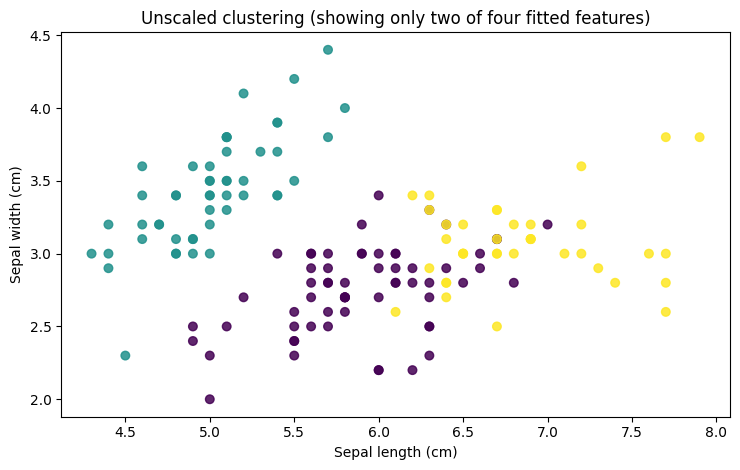

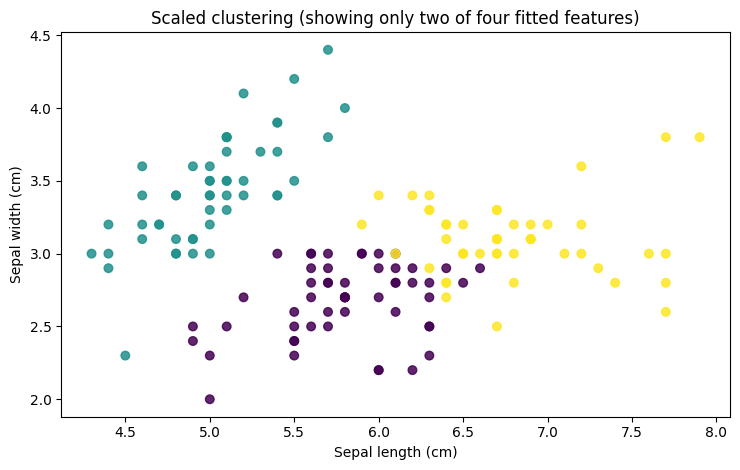

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()

X=iris.data.copy()
raw=KMeans(n_clusters=3,random_state=42,n_init=10).fit(X)
scaler=StandardScaler().fit(X)
X_scaled=scaler.transform(X)
scaled=KMeans(n_clusters=3,random_state=42,n_init=10).fit(X_scaled)
for name,features,fit in [('Original cm',X,raw),('Standardized z-scores',X_scaled,scaled)]:
    print(f'\n{name}: inertia={fit.inertia_:.4f}, silhouette={silhouette_score(features,fit.labels_):.4f}')
    print('Centroids in model coordinate system:\n',fit.cluster_centers_.round(3))
print('\nScaled centroids mapped BACK to cm (for interpretation; order is arbitrary):\n',
      scaler.inverse_transform(scaled.cluster_centers_).round(3))
for title,labels in [('Unscaled clustering',raw.labels_),('Scaled clustering',scaled.labels_)]:
    plt.figure(figsize=(7.5,4.8))
    plt.scatter(X[:,0],X[:,1],c=labels,cmap='viridis',alpha=.85,s=38)
    plt.xlabel('Sepal length (cm)');plt.ylabel('Sepal width (cm)')
    plt.title(title+' (showing only two of four fitted features)');plt.tight_layout();plt.show()


### Result interpretation and discussion
Raw K-means measures squared distances in cm (original feature units); standardized K-means uses z-scores and changes relative feature contributions. The centroid coordinates and inertia therefore live in **different feature spaces**. A plot of two features does **not** mean the model was trained on just two; both fits used all four.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is FOL? | Logic with objects, predicates, variables, and quantifiers. |
| What makes two people siblings? | They share a parent and are distinct people. |
| What is Greedy best-first? | Heuristic-priority search using h only. |
| Can misleading heuristics add expansions? | Yes; they may prioritize a branch that does not advance toward the goal. |
| Is K-means supervised? | No; it does not use class labels during fit. |
| What does scaling affect? | The distances, and thus centroids, cluster assignments, and inertia. |
| What is silhouette? | A dimensionless separation/cohesion measure within one feature space. |

| What is a binary relation? | A predicate connecting two objects, such as Parent(Rahman, Hasan). |
| Why not compare K-means inertia before and after scaling directly? | Scaling changes the numerical distances and therefore changes the units and magnitude of inertia. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 08 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | DLS/IDDFS root-visit tracing | 25 |
| Q2 | WEKA IBk preprocessing and J48 | 30 |
| Q3 | Train/test regression on chosen data | 35 |
| Q4 | Viva: cutoff, CV, scaling, regression, R² | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_08/Set_08_A.py) | [Q2 / B](Set_08/Set_08_B.py) | [Q3 / C](Set_08/Set_08_C.py) | [Q4 / D: Viva practice](Set_08/Set_08_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. DLS and IDDFS (25 marks)
**Question specification**  
`A→{B,C}, B→{D,E}, C→{F}, D→{H}, E→{I}, F→{G}`. Run DLS with depths 2 and 3, then IDDFS to G, display each iteration trace and count visits to root A.

### Theory and mathematical background
**Depth-Limited Search (DLS)** stops descending beyond an allowed depth $\ell$. A depth cutoff means the search might succeed with a larger limit; *failure* means no answer was found without such a cutoff.

**Iterative Deepening DFS (IDDFS)** performs DLS repeatedly at limits $0,1,2,\ldots$ until a goal is found:
$$IDDFS(\ell)=DLS(0),DLS(1),\dots,DLS(\ell).$$
It revisits shallow nodes, trading some repeated time for the memory efficiency of depth-first search. In a tree, DLS is commonly characterized by $O(b^\ell)$ time and $O(b\ell)$ space when sibling iterators are retained; IDDFS has roughly $O(b^d)$ time and $O(bd)$ space for a finite branching factor.

In [1]:
def depth_limited_search(graph, start, goal, limit):
    """Return path, status (success/cutoff/failure), expanded sequence."""
    expanded = []
    def visit(node, path, depth):
        expanded.append((node, depth))
        if node == goal: return path, 'success'
        if depth >= limit:
            eligible = [v for v in graph.get(node, []) if v not in path]
            return None, ('cutoff' if eligible else 'failure')
        had_cutoff = False
        for nxt in graph.get(node, []):
            if nxt in path: continue
            result, status = visit(nxt, path + [nxt], depth + 1)
            if status == 'success': return result, status
            if status == 'cutoff': had_cutoff = True
        return None, 'cutoff' if had_cutoff else 'failure'
    path, status = visit(start, [start], 0)
    return path, status, expanded

def iddfs(graph, start, goal, max_depth=10):
    iterations = []
    for limit in range(max_depth+1):
        path, status, expanded = depth_limited_search(graph, start, goal, limit)
        iterations.append((limit, path, status, expanded))
        if status == 'success': break
        if status == 'failure': break
    return path, iterations

def print_iddfs(graph, start, goal, max_depth=10):
    path, iterations = iddfs(graph, start, goal, max_depth)
    for limit, candidate, status, expanded in iterations:
        trace = ' -> '.join(node for node, depth in expanded)
        print(f'Limit={limit} | status={status:7} | expanded={trace} | path={candidate}')
    print(f'IDDFS path: {path}; root visits: {len(iterations)}')
    return path, iterations

graph={'A':['B','C'],'B':['D','E'],'C':['F'],
       'D':['H'],'E':['I'],'F':['G'],'G':[],'H':[],'I':[]}
for limit in [2,3]:
    path,status,expanded=depth_limited_search(graph,'A','G',limit)
    print(f'DLS(limit={limit}): status={status}; path={path}; trace={expanded}')
path,iterations=print_iddfs(graph,'A','G',8)
root_visits=sum(node=='A' for limit,p,status,tr in iterations for node,depth in tr)
print('Direct count of root visits across DLS iterations:',root_visits)
assert path==['A','C','F','G']


DLS(limit=2): status=cutoff; path=None; trace=[('A', 0), ('B', 1), ('D', 2), ('E', 2), ('C', 1), ('F', 2)]
DLS(limit=3): status=success; path=['A', 'C', 'F', 'G']; trace=[('A', 0), ('B', 1), ('D', 2), ('H', 3), ('E', 2), ('I', 3), ('C', 1), ('F', 2), ('G', 3)]
Limit=0 | status=cutoff  | expanded=A | path=None
Limit=1 | status=cutoff  | expanded=A -> B -> C | path=None
Limit=2 | status=cutoff  | expanded=A -> B -> D -> E -> C -> F | path=None
Limit=3 | status=success | expanded=A -> B -> D -> H -> E -> I -> C -> F -> G | path=['A', 'C', 'F', 'G']
IDDFS path: ['A', 'C', 'F', 'G']; root visits: 4
Direct count of root visits across DLS iterations: 4


### Result interpretation and discussion
The goal `G` lies at depth three via `A→C→F→G`. IDDFS expands root A once for each attempted limit (0,1,2,3), illustrating why shallow states repeat. That repetition buys the shallowest-goal guarantee of BFS (under finite branching and unit step cost), with DFS-like depth memory.

---
## Q2. WEKA Experiment (30 marks)
**Question specification**  
In WEKA on Iris, run IBk $k=5$ with 10-fold CV, apply normalization/standardization and repeat IBk, then run J48. Record accuracy/confusion matrices and compare which configuration performs best.

### Theory and mathematical background
**WEKA Explorer** is a GUI workbench for data mining. In this experiment:
- `J48` is a C4.5-style decision-tree implementation.
- `IBk` is a nearest-neighbor classifier; the value of $k$ controls the number of neighbors.
- In **10-fold cross-validation**, the dataset is partitioned into ten folds. Each fold is evaluated once using a model trained on the remaining folds. A common summary is:
$$\mathrm{CV\ accuracy}=\frac{\text{total held-out correct predictions}}{\text{total held-out predictions}}.$$

A saved **WEKA result buffer** is required evidence: a Python evaluation of a similar method must not be presented as if it were the output of WEKA. To prevent preprocessing leakage, use WEKA's **FilteredClassifier** when evaluating scaling under cross-validation.

In [2]:
from scipy.io import arff
from pathlib import Path
from collections import Counter
# Use the same data file in a notebook and in a standalone Python script.
try:
    iris_path = Path(__file__).with_name("iris.arff")
except NameError:  # Jupyter notebooks do not define __file__.
    iris_path = Path("Set_08/iris.arff") if Path("Set_08/iris.arff").exists() else Path("iris.arff")
records, meta=arff.loadarff(iris_path)
counts=Counter(x.decode('utf-8') for x in records['class'])
print('ARFF for WEKA:',iris_path.resolve())
print('Attributes:',meta.names())
print('Instances:',len(records),'| class distribution:',dict(counts))
assert len(records)==150
print("NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.")


ARFF for WEKA: /Users/macbookair/Desktop/Disk Sajjad/IU ICT 2020-21/Academic Files/4th Year 2nd Semester/ICT-4202 Artificial Intelligence and Machine Learning Laboratory/ICT-4202-AI-ML-Laboratory/Set_08/iris.arff
Attributes: ['sepallength', 'sepalwidth', 'petallength', 'petalwidth', 'class']
Instances: 150 | class distribution: {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}
NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.


### Required WEKA execution checklist
1. **Preprocess:** Open `iris.arff`; confirm 150 instances and choose the **nominal `class`** attribute.
2. **Classify:** Choose `lazy.IBk`, set **KNN=5**, enable 10-fold cross-validation, and run. Save the output buffer and confusion matrix.
3. **Preprocessed IBk:** In the **Classify** tab choose `meta.FilteredClassifier`. Set `filter=weka.filters.unsupervised.attribute.Standardize` (or `Normalize`), with `classifier=weka.classifiers.lazy.IBk` and `KNN=5`. Run 10-fold CV again. **FilteredClassifier is recommended** so the standardization parameters are learned inside each training fold rather than from the entire dataset before validation.
4. **Classify:** Run `trees.J48` with the same 10-fold CV protocol. Save the result buffer.
5. Compare **accuracy and confusion matrix** and record the best *observed* configuration.

| Run | Algorithm and configuration | Accuracy (%) | Confusion matrix |
|:--|:--|--:|:--|
| 1 | IBk, k=5, unscaled | *from WEKA* | *from WEKA* |
| 2 | FilteredClassifier(Standardize + IBk k=5) | *from WEKA* | *from WEKA* |
| 3 | J48 | *from WEKA* | *from WEKA* |

**Evidence required:** Capture the classifier output/result list in WEKA. The above Python cell verifies only the local ARFF dataset; these blank WEKA results are intentional.

---
## Q3. Regression Programming (35 marks)
**Question specification**  
Create at least ten numerical observations for a reasonable prediction problem, split train/test, fit LinearRegression; show slope/intercept, train/test $R^2$, two predictions for unseen inputs, plot data/model output, and interpret one limitation.

### Theory and mathematical background
Simple linear regression estimates a numerical response from a predictor:
$$\hat y_i=\beta_0+\beta_1x_i.$$
The least-squares estimator minimizes
$$SSE=\sum_{i=1}^{n}\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)^2,$$
with $\hat\beta_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}$ and $\hat\beta_0=\bar y-\hat\beta_1\bar x$.

The coefficient of determination is
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
An in-sample $R^2$ measures fit to the data used; test $R^2$ estimates performance on unseen data. With small test sets, the latter can be unstable or negative.

Samples: 16 | Train: 12 | Test: 4
Slope=4.0211, intercept=11.9432
Train R²=0.9806
Test  R²=0.9909
Prediction for 7.5 study hours: 42.101
Prediction for 18.0 study hours: 84.323


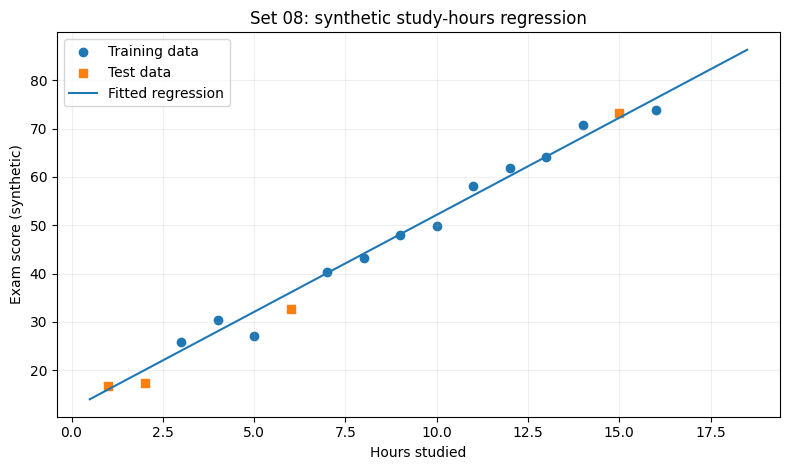

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
# Student practice dataset (synthetic): study hours -> exam score.
# Explicitly illustrative, NOT student survey/observed exam results.
hours=np.arange(1,17,dtype=float)
rng=np.random.default_rng(42)
scores=12+4.0*hours+rng.normal(0,2.5,size=hours.size)
X=hours.reshape(-1,1)
X_train,X_test,y_train,y_test=train_test_split(X,scores,test_size=.25,random_state=42)
model=LinearRegression().fit(X_train,y_train)
print('Samples:',len(hours),'| Train:',len(y_train),'| Test:',len(y_test))
print(f'Slope={model.coef_[0]:.4f}, intercept={model.intercept_:.4f}')
print(f'Train R²={r2_score(y_train,model.predict(X_train)):.4f}')
print(f'Test  R²={r2_score(y_test,model.predict(X_test)):.4f}')
for unseen in [7.5,18.0]:
    print(f'Prediction for {unseen} study hours: {model.predict([[unseen]])[0]:.3f}')
line=np.linspace(0.5,18.5,120).reshape(-1,1)
plt.figure(figsize=(8,4.8))
plt.scatter(X_train[:,0],y_train,label='Training data')
plt.scatter(X_test[:,0],y_test,marker='s',label='Test data')
plt.plot(line[:,0],model.predict(line),label='Fitted regression')
plt.xlabel('Hours studied');plt.ylabel('Exam score (synthetic)')
plt.title('Set 08: synthetic study-hours regression')
plt.grid(alpha=.2);plt.legend();plt.tight_layout();plt.show()


### Result interpretation and discussion
The data intentionally contain random variation and are **synthetic teaching examples**. Test $R^2$ assesses prediction on held-out data but has high sampling variance with only four test cases. A prediction at 18 hours extrapolates beyond the observed range (1–16), so its reliability is weaker than interpolation within the training range. No causal claim is justified.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Depth cutoff? | A search boundary that may hide deeper goals. |
| Why IDDFS repeats root? | Because each larger depth limit starts a new DFS. |
| Cross-validation? | Repeated train/evaluate cycles on different held-out folds. |
| What is data leakage? | Using test/validation information while training or preprocessing. |
| What is standardization? | Subtract training mean and divide by training standard deviation. |
| Train versus test R²? | In-sample fit versus fit on held-out observations. |
| What is extrapolation? | Predicting beyond the range of available training inputs. |

| What is the difference between normalization and standardization? | Min-max normalization usually rescales to a range such as 0 to 1; standardization subtracts the mean and divides by standard deviation. |
| Why should preprocessing be fit within each training fold? | Fitting preprocessing on all data can leak information into cross-validation estimates. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 09 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | BFS versus DFS on branching graph | 30 |
| Q2 | A* and admissibility test | 30 |
| Q3 | K-means elbow/silhouette model selection | 30 |
| Q4 | Viva: shortest path, admissibility, inertia, silhouette | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_09/Set_09_A.py) | [Q2 / B](Set_09/Set_09_B.py) | [Q3 / C](Set_09/Set_09_C.py) | [Q4 / D: Viva practice](Set_09/Set_09_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. BFS and DFS Comparison (30 marks)
**Question specification**  
`A→{B,C}, B→{D,E}, C→{F}, D→{H}, E→{G}, F→{G}, G→{}, H→{G}`. Find A to G by BFS and DFS, print paths and expansion traces. Reverse adjacency order and compare. Explain why BFS finds a minimum-edge route.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

In [1]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

graph={'A':['B','C'],'B':['D','E'],'C':['F'],'D':['H'],
       'E':['G'],'F':['G'],'G':[],'H':['G']}
reversed_graph={u:list(reversed(v)) for u,v in graph.items()}
for name, variant in [('Original adjacency',graph),('Reversed adjacency',reversed_graph)]:
    print('\n'+name)
    for algorithm,fn in [('BFS',bfs),('DFS',dfs)]:
        path,expanded=fn(variant,'A','G')
        print(f'  {algorithm}: path={path}; edges={len(path)-1 if path else None}; expanded={expanded}')



Original adjacency
  BFS: path=['A', 'B', 'E', 'G']; edges=3; expanded=['A', 'B', 'C', 'D', 'E', 'F', 'H', 'G']
  DFS: path=['A', 'B', 'D', 'H', 'G']; edges=4; expanded=['A', 'B', 'D', 'H', 'G']

Reversed adjacency
  BFS: path=['A', 'C', 'F', 'G']; edges=3; expanded=['A', 'C', 'B', 'F', 'E', 'D', 'G']
  DFS: path=['A', 'C', 'F', 'G']; edges=3; expanded=['A', 'C', 'F', 'G']


### Result interpretation and discussion
BFS processes all paths of depth $d$ before any at depth $d+1$, so for equal edge weights the first goal reached has the fewest edges. Changing the adjacency order can change **which** equal-depth route is returned. DFS may instead explore an additional deep detour through `D→H` before returning to other branches.

---
## Q2. A* and Heuristic Admissibility (30 marks)
**Question specification**  
`S-A=1, S-B=5, A-C=2, A-D=4, B-D=1, C-G=5, D-G=2`. Choose an admissible heuristic, show g/h/f and best route. Make one heuristic overestimate and discuss why admissibility matters.

### Theory and mathematical background
A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

graph={'S':[('A',1),('B',5)],'A':[('C',2),('D',4)],
       'B':[('D',1)],'C':[('G',5)],'D':[('G',2)],'G':[]}
# True remaining costs: S=7, A=6, B=3, C=5, D=2, G=0.
# The base heuristic never overestimates these true values.
h={'S':6,'A':5,'B':3,'C':4,'D':2,'G':0}
true_to_goal={'S':7,'A':6,'B':3,'C':5,'D':2,'G':0}
print('Admissibility check (h <= optimal remaining cost):')
for node in h:
    print(node,'h=',h[node],'true remaining=',true_to_goal[node],
          'admissible=',h[node]<=true_to_goal[node])
optimal_path,optimal_cost,trace=astar(graph,h,'S','G')
print('\nA* with admissible h:',optimal_path,'| total cost:',optimal_cost)
display_astar_trace(trace)
bad_h=dict(h);bad_h['A']=100  # deliberately overestimates A's true cost-to-go (6)
bad_path,bad_cost,bad_trace=astar(graph,bad_h,'S','G')
print('A* with nonadmissible h(A)=100:',bad_path,'| total cost:',bad_cost)
display_astar_trace(bad_trace)
assert optimal_cost==7
assert bad_cost>=optimal_cost


Admissibility check (h <= optimal remaining cost):
S h= 6 true remaining= 7 admissible= True
A h= 5 true remaining= 6 admissible= True
B h= 3 true remaining= 3 admissible= True
C h= 4 true remaining= 5 admissible= True
D h= 2 true remaining= 2 admissible= True
G h= 0 true remaining= 0 admissible= True

A* with admissible h: ['S', 'A', 'D', 'G'] | total cost: 7
Node     g(n)     h(n)     f(n)
   S        0        6        6
   A        1        5        6
   C        3        4        7
   D        5        2        7
   G        7        0        7
A* with nonadmissible h(A)=100: ['S', 'B', 'D', 'G'] | total cost: 8
Node     g(n)     h(n)     f(n)
   S        0        6        6
   B        5        3        8
   D        6        2        8
   G        8        0        8


### Result interpretation and discussion
For the admissible heuristic, optimal route `S→A→D→G` costs $1+4+2=7$. Choosing $h(A)=100$ **overestimates** the actual remaining cost (6) and can cause A* to return the inferior `S→B→D→G` cost 8 before exploring A. An overestimate does not always change the answer, but it removes the usual optimality guarantee; this graph provides a concrete counterexample.

---
## Q3. K-means Model Selection (30 marks)
**Question specification**  
First two Iris features, $k=2,3,4,5$. Tabulate inertia and silhouette; plot an elbow curve and silhouette by $k$; choose a $k$ and display final clusters/centers. Explain why inertia usually decreases as $k$ grows.

### Theory and mathematical background
**K-means** is an unsupervised clustering method that alternates assigning samples to the nearest centroid and updating centroids. For $K$ clusters, it seeks to minimize
$$J=\sum_{i=1}^{n}\left\|\mathbf x_i-\boldsymbol\mu_{z_i}\right\|_2^2.$$
`inertia_` is the final within-cluster sum of squares. The silhouette of a sample is
$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},$$
where $a(i)$ is average within-cluster distance and $b(i)$ is its smallest mean distance to another cluster. Larger silhouette generally indicates better-separated clusters. **Cluster IDs are arbitrary** and are not species class labels.

Feature scaling changes the distance geometry and inertia's units; compare inertia only for models using comparable feature representations.

 k  inertia  silhouette
 2  58.2041      0.4630
 3  37.0507      0.4451
 4  27.9902      0.4249
 5  20.9968      0.4101


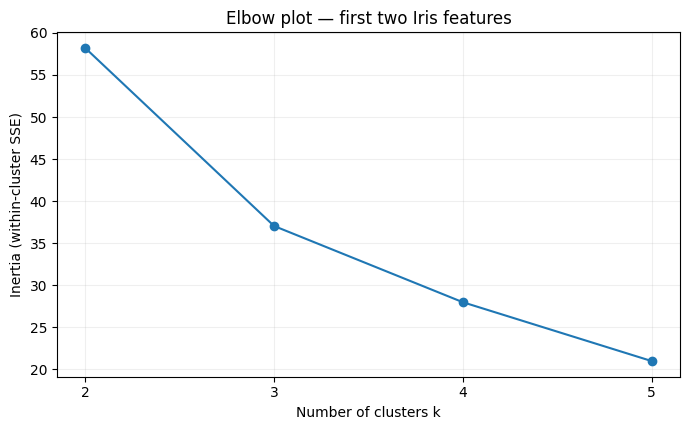

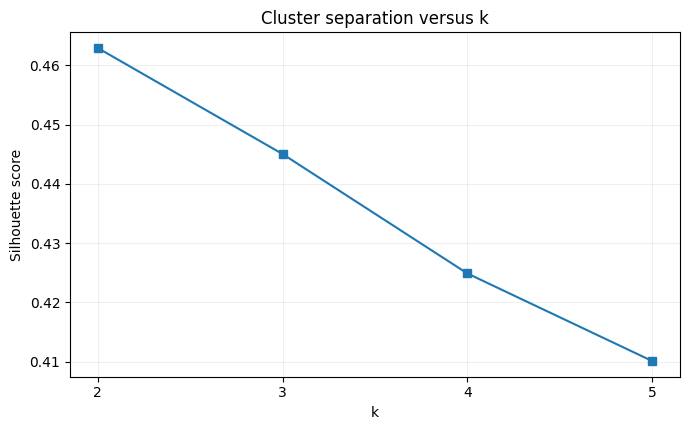

Chosen by maximum silhouette: 2
Centers:
 [[5.224 3.131]
 [6.61  2.966]]


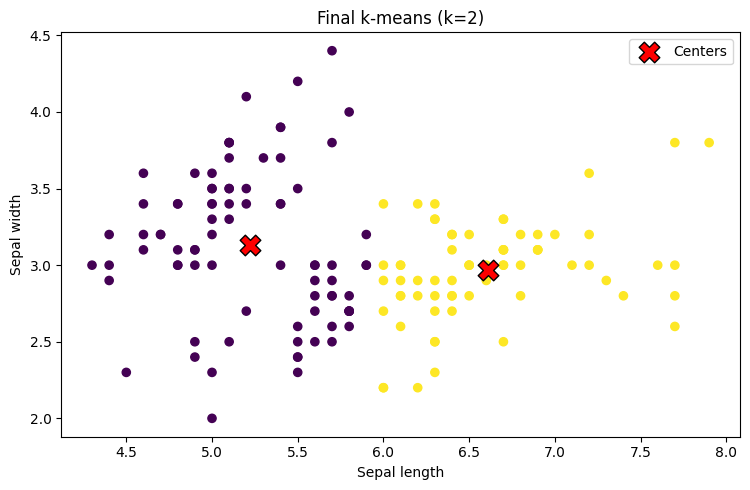

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
iris = load_iris()

X=iris.data[:, :2]
runs=[]; models={}
for k in [2,3,4,5]:
    mdl=KMeans(n_clusters=k,random_state=42,n_init=10).fit(X)
    models[k]=mdl
    runs.append({'k':k,'inertia':mdl.inertia_,'silhouette':silhouette_score(X,mdl.labels_)})
table=pd.DataFrame(runs)
print(table.round(4).to_string(index=False))
chosen_k=int(table.loc[table.silhouette.idxmax(),'k'])
best=models[chosen_k]
plt.figure(figsize=(7,4.4))
plt.plot(table.k,table.inertia,marker='o');plt.xticks([2,3,4,5]);plt.xlabel('Number of clusters k')
plt.ylabel('Inertia (within-cluster SSE)');plt.title('Elbow plot — first two Iris features')
plt.grid(alpha=.2);plt.tight_layout();plt.show()
plt.figure(figsize=(7,4.4))
plt.plot(table.k,table.silhouette,marker='s');plt.xticks([2,3,4,5]);plt.xlabel('k')
plt.ylabel('Silhouette score');plt.title('Cluster separation versus k')
plt.grid(alpha=.2);plt.tight_layout();plt.show()
print('Chosen by maximum silhouette:',chosen_k)
print('Centers:\n',best.cluster_centers_.round(3))
plt.figure(figsize=(7.6,5))
plt.scatter(X[:,0],X[:,1],c=best.labels_,cmap='viridis',s=35)
plt.scatter(best.cluster_centers_[:,0],best.cluster_centers_[:,1],marker='X',s=220,
            edgecolors='black',c='red',label='Centers')
plt.xlabel('Sepal length');plt.ylabel('Sepal width');plt.title(f'Final k-means (k={chosen_k})')
plt.legend();plt.tight_layout();plt.show()


### Result interpretation and discussion
Adding clusters gives the algorithm more centroids and (at a global optimum) cannot increase the smallest possible within-cluster SSE. Practical K-means may converge to local minima, so individual initialization choices need not be monotonic, but the reported values with consistent settings should typically decline. Silhouette balances compactness and separation.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Why BFS returns a shortest path? | FIFO exploration of increasing depth in an unweighted graph. |
| Can DFS give a longer path? | Yes; DFS does not prioritize depth globally. |
| Admissible heuristic? | h never overestimates the true remaining cheapest cost. |
| A* priority? | f(n)=g(n)+h(n). |
| What is inertia? | Sum of within-cluster squared deviations. |
| What is an elbow? | A point where inertia improvement slows markedly. |
| What does silhouette measure? | Similarity within the assigned cluster versus nearest other cluster. |

| What happens if a heuristic overestimates the cost? | A* may lose its shortest-cost guarantee because the heuristic is not admissible. |
| Why does K-means inertia usually decrease as k increases? | More centers can reduce or preserve the sum of distances to the nearest assigned center. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.

---
# Set 10 — Final Laboratory Examination
**Department of Information and Communication Technology, Islamic University**  


> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Integrated forward-chaining agent | 25 |
| Q2 | BFS, Greedy, A* with assigned costs | 35 |
| Q3 | Iris classification metrics comparison | 30 |
| Q4 | Viva: knowledge base, shortest versus cheapest, F1 | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_10/Set_10_A.py) | [Q2 / B](Set_10/Set_10_B.py) | [Q3 / C](Set_10/Set_10_C.py) | [Q4 / D: Viva practice](Set_10/Set_10_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Integrated Knowledge-Based Agent (25 marks)
**Question specification**  
`TemperatureHigh`; `TemperatureHigh→Hot`; `Hot AND Humid→Uncomfortable`; `Uncomfortable→FanOn`; `Rain→Humid`. Run forward chaining for: high temperature only; high temperature + Humid; high temperature + Rain; show traces and given-versus-inferred facts.

### Theory and mathematical background
A knowledge base (KB) stores **facts** and **rules**. In propositional forward chaining, rules have premises and a conclusion. For example:
$$P\land Q\Rightarrow R.$$
A rule fires when all its premises are already known. This is repeated until no new conclusion can be inferred (the *fixed point*).

For implication, $P\Rightarrow Q\equiv \neg P\lor Q$; it is false only when $P$ is true and $Q$ is false. Forward chaining for definite Horn-style rules is a data-driven form of logical inference.

In [1]:

def forward_chain(initial_facts, rules):
    """Data-driven inference: rules are (premise-set, conclusion) pairs."""
    known = set(initial_facts)
    trace = []
    while True:
        newly_added = False
        for premises, conclusion in rules:
            if premises.issubset(known) and conclusion not in known:
                known.add(conclusion)
                trace.append((sorted(premises), conclusion))
                newly_added = True
        if not newly_added:
            break
    return known, trace

def print_inference(label, initial, rules):
    known, trace = forward_chain(initial, rules)
    print(f"\n{label} | Initial facts: {sorted(initial)}")
    for i, (prem, conclusion) in enumerate(trace, 1):
        print(f"  {i}. {prem}  =>  {conclusion}")
    if not trace: print("  No new rule fired.")
    print('Final facts:', sorted(known))
    return known, trace

rules=[({'TemperatureHigh'},'Hot'),({'Hot','Humid'},'Uncomfortable'),
       ({'Uncomfortable'},'FanOn'),({'Rain'},'Humid')]
cases=[('TemperatureHigh only',{'TemperatureHigh'}),
       ('TemperatureHigh + Humid',{'TemperatureHigh','Humid'}),
       ('TemperatureHigh + Rain',{'TemperatureHigh','Rain'})]
for title,given in cases:
    known,trace=print_inference(title,given,rules)
    print('Given (asserted):',sorted(given))
    print('Derived (inferred):',sorted(known-given),'| FanOn?', 'FanOn' in known)



TemperatureHigh only | Initial facts: ['TemperatureHigh']
  1. ['TemperatureHigh']  =>  Hot
Final facts: ['Hot', 'TemperatureHigh']
Given (asserted): ['TemperatureHigh']
Derived (inferred): ['Hot'] | FanOn? False

TemperatureHigh + Humid | Initial facts: ['Humid', 'TemperatureHigh']
  1. ['TemperatureHigh']  =>  Hot
  2. ['Hot', 'Humid']  =>  Uncomfortable
  3. ['Uncomfortable']  =>  FanOn
Final facts: ['FanOn', 'Hot', 'Humid', 'TemperatureHigh', 'Uncomfortable']
Given (asserted): ['Humid', 'TemperatureHigh']
Derived (inferred): ['FanOn', 'Hot', 'Uncomfortable'] | FanOn? True

TemperatureHigh + Rain | Initial facts: ['Rain', 'TemperatureHigh']
  1. ['TemperatureHigh']  =>  Hot
  2. ['Rain']  =>  Humid
  3. ['Hot', 'Humid']  =>  Uncomfortable
  4. ['Uncomfortable']  =>  FanOn
Final facts: ['FanOn', 'Hot', 'Humid', 'Rain', 'TemperatureHigh', 'Uncomfortable']
Given (asserted): ['Rain', 'TemperatureHigh']
Derived (inferred): ['FanOn', 'Hot', 'Humid', 'Uncomfortable'] | FanOn? True


### Result interpretation and discussion
In the first case, `Hot` is inferred but `Humid` is missing. In the second case, Humid is **given** and `Uncomfortable`/`FanOn` follow. In the third, `Rain` is **given** and `Humid` is **inferred** before the joint rule can fire. The final conclusions match the same logical implication chain.

---
## Q2. Integrated Search Task (35 marks)
**Question specification**  
`S→{A,B}, A→{C,D}, B→{D,E}, C→{G}, D→{G}, E→{G}`. Assign *positive costs* and a *reasonable heuristic* (not specified by question); run BFS, Greedy and A*, showing expansion traces, route and cost. Explain minimum edges versus minimum cost.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

A heuristic $h(n)$ estimates remaining cost from state $n$ to the goal. **Greedy best-first search** prioritizes only $h(n)$, so it need not find the lowest-cost route.

**A\* search** uses
$$g(n)=\text{cost from start to }n,\qquad f(n)=g(n)+h(n).$$
A heuristic is **admissible** when
$$0\le h(n)\le h^*(n),$$
where $h^*(n)$ is the true cheapest remaining cost. Under suitable graph-search conditions, admissible heuristics with cost updates/reopening allow optimal A\*; non-admissible heuristics remove this guarantee.

In [2]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

from itertools import count

import heapq

def astar(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    best_g = {start: 0}
    expanded = []
    while heap:
        f, _, g, node, path = heapq.heappop(heap)
        if g > best_g.get(node, float('inf')): continue  # stale entry
        expanded.append((node, g, h[node], f))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            new_g = g + weight
            if new_g < best_g.get(nxt, float('inf')):
                best_g[nxt] = new_g
                heapq.heappush(heap, (new_g+h[nxt], next(counter), new_g, nxt, path+[nxt]))
    return None, float('inf'), expanded

def greedy_weighted(graph, h, start, goal):
    counter = count()
    heap = [(h[start], next(counter), 0, start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, g, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append((node, g, h[node]))
        if node == goal: return path, g, expanded
        for nxt, weight in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(counter), g+weight, nxt, path+[nxt]))
    return None, float('inf'), expanded

def display_astar_trace(trace):
    print("Node     g(n)     h(n)     f(n)")
    for node, g, h, f in trace:
        print(f"{node:>4} {g:>8} {h:>8} {f:>8}")

# Positive weights and an admissible (but deliberately uneven) heuristic are
# our EXPLICIT CHOICES: the examination question does not specify numbers.
weighted={'S':[('A',1),('B',2)],'A':[('C',9),('D',8)],
          'B':[('D',1),('E',4)],'C':[('G',7)],'D':[('G',2)],
          'E':[('G',6)],'G':[]}
unweighted={u:[v for v,c in edges] for u,edges in weighted.items()}
h={'S':4,'A':1,'B':3,'C':2,'D':1,'E':5,'G':0}
edge_cost={(u,v):cost for u,edges in weighted.items() for v,cost in edges}
def path_cost(path):
    return sum(edge_cost[(u,v)] for u,v in zip(path,path[1:])) if path else None
bfs_path,bfs_trace=bfs(unweighted,'S','G')
greedy_path,greedy_cost,greedy_trace=greedy_weighted(weighted,h,'S','G')
a_path,a_cost,a_trace=astar(weighted,h,'S','G')
print('BFS    :',bfs_path,'| expanded:',bfs_trace,'| cost:',path_cost(bfs_path))
print('Greedy :',greedy_path,'| expanded:',greedy_trace,'| cost:',greedy_cost)
print('A*     :',a_path,'| expanded:',a_trace,'| cost:',a_cost)
display_astar_trace(a_trace)
assert a_cost == 5 and path_cost(bfs_path) > a_cost


BFS    : ['S', 'A', 'C', 'G'] | expanded: ['S', 'A', 'B', 'C', 'D', 'E', 'G'] | cost: 17
Greedy : ['S', 'A', 'D', 'G'] | expanded: [('S', 0, 4), ('A', 1, 1), ('D', 9, 1), ('G', 11, 0)] | cost: 11
A*     : ['S', 'B', 'D', 'G'] | expanded: [('S', 0, 4, 4), ('A', 1, 1, 2), ('B', 2, 3, 5), ('D', 3, 1, 4), ('G', 5, 0, 5)] | cost: 5
Node     g(n)     h(n)     f(n)
   S        0        4        4
   A        1        1        2
   B        2        3        5
   D        3        1        4
   G        5        0        5


### Result interpretation and discussion
**Why the two criteria differ:** all four S→G routes in the given topology contain *three edges*. BFS therefore chooses one of several **minimum-edge** routes using adjacency order, here `S→A→C→G` with assigned cost $1+9+7=17$. A* evaluates weights and chooses `S→B→D→G` with lower cost $2+1+2=5$. Greedy may be misled by the smaller $h(A)$ and select a more expensive route. These cost numbers and heuristics are **illustrative author choices**, not values printed in the exam sheet.

---
## Q3. Classification (30 marks)
**Question specification**  
Using Iris 70/30 stratified split, compare k-NN $k=3$ and decision tree `max_depth=3`, with accuracy, confusion matrices, precision/recall/F1. Compare errors and state which model you prefer for this fixed run.

### Theory and mathematical background
**k-Nearest Neighbors (k-NN)** predicts the majority label among the $k$ nearest training samples. A common distance is Euclidean:
$$d(\mathbf x,\mathbf z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$
Standardization rescales a feature using training-set statistics:
$$z_j=\frac{x_j-\mu_j^{\mathrm{train}}}{\sigma_j^{\mathrm{train}}}.$$
**Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$ for binary labels (or total correct / total cases for multiclass). A confusion matrix $C_{ij}$ counts instances of actual class $i$ predicted as class $j$. Fit scaling on training samples only to prevent leakage.

A **decision tree** recursively chooses feature thresholds that reduce node impurity. One measure is Gini impurity:
$$Gini(D)=1-\sum_{c=1}^{K}p(c\mid D)^2.$$
Restricting `max_depth` reduces complexity but can cause underfitting; large or unrestricted depth can memorize training samples and overfit.

For each class, $Precision=\frac{TP}{TP+FP}$, $Recall=\frac{TP}{TP+FN}$, and $F_1=\frac{2PR}{P+R}$. Macro averages assign equal weight to every class.

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    stratify=y, random_state=42)
print('Iris samples:', X.shape, '| train:', len(y_train), '| test:', len(y_test))
print('Class order:', list(iris.target_names))

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_fscore_support
candidates={'k-NN (k=3)':KNeighborsClassifier(n_neighbors=3),
            'Decision tree (depth=3)':DecisionTreeClassifier(max_depth=3,random_state=42)}
rows=[]
for name,model in candidates.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    accuracy=accuracy_score(y_test,pred)
    p,r,f1,_=precision_recall_fscore_support(y_test,pred,average='macro',zero_division=0)
    rows.append({'model':name,'accuracy':accuracy,'precision_macro':p,
                 'recall_macro':r,'f1_macro':f1})
    errors=np.flatnonzero(pred!=y_test)
    print('\n'+name)
    print('Confusion matrix (actual rows):\n',confusion_matrix(y_test,pred))
    print('Misclassified TEST ROW POSITIONS:',errors.tolist())
    for idx in errors[:10]:
        print('  Row',idx,'| actual:',iris.target_names[y_test[idx]],
              '| predicted:',iris.target_names[pred[idx]])
comparison=pd.DataFrame(rows)
print(comparison.round(4).to_string(index=False))
winner=comparison.sort_values(['accuracy','f1_macro','model'],ascending=[False,False,True]).iloc[0]
print('Preferred for this particular split (accuracy then macro F1):',winner['model'])


Iris samples: (150, 4) | train: 105 | test: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

k-NN (k=3)
Confusion matrix (actual rows):
 [[15  0  0]
 [ 0 15  0]
 [ 0  2 13]]
Misclassified TEST ROW POSITIONS: [2, 42]
  Row 2 | actual: virginica | predicted: versicolor
  Row 42 | actual: virginica | predicted: versicolor

Decision tree (depth=3)
Confusion matrix (actual rows):
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]
Misclassified TEST ROW POSITIONS: [39]
  Row 39 | actual: versicolor | predicted: virginica
                  model  accuracy  precision_macro  recall_macro  f1_macro
             k-NN (k=3)    0.9556           0.9608        0.9556    0.9554
Decision tree (depth=3)    0.9778           0.9792        0.9778    0.9778
Preferred for this particular split (accuracy then macro F1): Decision tree (depth=3)


### Result interpretation and discussion
The preferred algorithm is chosen using the **displayed metrics for this fixed split**, prioritizing accuracy and breaking ties by macro F1. Another split may reverse the ranking. The 45-case test set is relatively small, and neither method is automatically superior; real research would compare repeated cross-validation and independent holdout performance.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is an asserted fact? | A proposition initially placed into the KB. |
| What is an inferred fact? | A new proposition derived using rules. |
| Difference between BFS and A*? | BFS minimizes edge count; A* uses costs g+h. |
| Greedy drawback? | It may favor a low h while ignoring high path cost g. |
| Confusion matrix? | Counts of actual versus predicted classes. |
| Precision? | Share of predicted positives that are truly positive. |
| Recall? | Share of actual positives correctly predicted. |
| F1? | Harmonic mean of precision and recall. |

| What is forward chaining? | Start with known facts and repeatedly apply rules whose premises are satisfied. |
| Does a shortest path in edges always have the lowest cost? | No. When edges have different costs, a path with fewer edges can cost more. |
| What is the F1 score? | The harmonic mean of precision and recall: F1 = 2PR/(P+R), when P+R is positive. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.